<p align="center">
  <img src="assets/hero_proje.svg" width="100%" alt="Gün 54 — Kuru fasulye tasnifi: PCA ve 27 algoritma">
</p>

<p align="center">
  <img src="https://img.shields.io/badge/G%C3%BCn-54-0B3A52?style=for-the-badge" alt="Gün 54">
  <img src="https://img.shields.io/badge/Konu-PCA_(Proje)-E5A100?style=for-the-badge" alt="Konu">
  <img src="https://img.shields.io/badge/Seviye-Ba%C5%9Flang%C4%B1%C3%A7_%E2%86%92_Orta-16A34A?style=for-the-badge" alt="Seviye">
  <img src="https://img.shields.io/badge/Veri-Dry_Bean_(Kaggle)-0EA5C6?style=for-the-badge" alt="Veri">
  <img src="https://img.shields.io/badge/Algoritma-27_%2B_taban-D1495B?style=for-the-badge" alt="Algoritma">
</p>

<table>
<tr><td width="25%" valign="top" align="center"><h3>🧪</h3><b>Sızıntısız boru hattı</b><br><br>Ölçekleme + PCA + model,<br><b>her katta baştan</b> kurulur<br><br></td><td width="25%" valign="top" align="center"><h3>🏁</h3><b>İki dünyada yarış</b><br><br>27 algoritma <b>ham 16 ölçüyle</b><br>ve <b>PCA ile</b> yarışır<br><br></td><td width="25%" valign="top" align="center"><h3>🎚️</h3><b>k bir düğmedir</b><br><br>Bileşen sayısı model ile<br><b>birlikte ayarlanır</b><br><br></td><td width="25%" valign="top" align="center"><h3>🚨</h3><b>Yeni tür avı</b><br><br>PCA'nın <b>yeniden kurma hatası</b><br>ile tanımadığı fasulyeyi yakala<br><br></td></tr>
</table>

<table><tr><td>

<img src="assets/etiket_hedef.svg" height="34" alt="Hedefler">

**Bu notebook'un sonunda şunları yapabiliyor olacaksınız:**

- 🫘 Gerçek bir **Kaggle** verisiyle (13.611 kuru fasulye, 16 şekil ölçüsü, 7 tür) **uçtan uca** proje kurmak
- 🧼 Kopya satırları ve **sızıntı** risklerini (kopya, PCA, ölçekleme) **ölçerek** göstermek
- 🔬 PCA'yı yakından incelemek: dirsek, yükler, harita, **kaç bileşen?**
- 🏁 **27 algoritmayı** (+ taban) **ham ölçüler** ve **PCA** ile aynı katlarda yarıştırmak
- 📊 PCA'nın **doğruluğa, hıza ve her algoritma ailesine** etkisini istatistikle okumak
- 🎚️ Bileşen sayısını **hiperparametre** olarak ayarlamak ve önceden yazılmış bir **seçim kuralı** uygulamak
- 🏆 Test setini **yalnızca bir kez** açıp sonucu dürüstçe raporlamak; hata, segment, kalibrasyon ve **maliyet** analizi yapmak
- 🚨 PCA'yı **anomali (yeni tür) avında** kullanmak
- 💾 Modeli kaydedip **ayrı bir süreçte** yükleyerek test etmek

Her adımda neden o kararı verdiğimiz **Türkçe yorum satırlarıyla** açıklanır.

</td></tr></table>

<p align="center">
  <img src="assets/yol_haritasi_proje.svg" width="100%" alt="Proje yol haritası: 16 bölüm">
</p>

### 🧭 Hızlı Erişim

| # | Bölüm | Ana soru |
|:-:|:--|:--|
| 1 | [Kurulum](#p1) | Hangi araçlar, hangi tohum? |
| 2 | [Senaryo, veri, ölçütler](#p2) | Ne tahmin ediyoruz, başarıyı nasıl ölçeriz? |
| 3 | [Veri kalitesi](#p3) | Kopya, aykırı değer, eksik var mı? |
| 4 | [Keşif (test kilitli)](#p4) | Veri nasıl görünüyor, ölçüler neden birbirine bağlı? |
| 5 | [Dürüst bölme](#p5) | Kopya ve PCA sızıntısı ne kadar yanıltır? |
| 6 | [PCA yakından](#p6) | Kaç bileşen, ne anlama geliyorlar? |
| 7 | [Büyük yarış](#p7) | 27 algoritma, ham ↔ PCA |
| 8 | [PCA'nın etkisi](#p8) | Doğruluk, hız ve aileler: kim kazandı? |
| 9 | [Bileşen sayısı eğrisi](#p9) | k arttıkça ne olur? |
| 10 | [Hiperparametre ayarı](#p10) | PCA + model birlikte ayarlanınca? |
| 11 | [Yorumlama](#p11) | Hangi ölçüler ve hangi bilgi gerçekten gerekli? |
| 12 | [Final test](#p12) | Test setinde dürüst sonuç |
| 13 | [Segment denetimi](#p13) | Hangi dilimlerde zayıfız, maliyet ne? |
| 14 | [Yeni tür avı](#p14) | PCA ile bilinmeyeni yakalayabilir miyiz? |
| 15 | [Model kaydı](#p15) | Kaydet, ayrı süreçte yükle |
| 16 | [Özet](#p16) | Sonuçlar, quiz, ödevler, kaynakça |

<a id="p1"></a>

<p align="center">
  <img src="assets/proje_01.svg" width="100%" alt="Bölüm 1">
</p>

Kütüphaneleri, tohumu, renkleri ve yardımcı işlevleri tek hücrede topluyoruz. Tüm rastgelelik **`RANDOM_STATE = 42`** ile sabitlenir; böylece sonuçlar her çalıştırmada aynıdır.

In [1]:
# ── Kütüphaneler ─────────────────────────────────────────────
import os, time, warnings, sys, json, subprocess, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy, sklearn, joblib, lightgbm, xgboost, catboost
from IPython.display import Image, Markdown, display
from matplotlib.animation import FuncAnimation, PillowWriter
from joblib import Parallel, delayed
from scipy import stats
from scipy.stats import loguniform, randint, uniform

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     RandomizedSearchCV, cross_val_predict)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score, log_loss, roc_auc_score,
                             confusion_matrix, classification_report)
from sklearn.inspection import permutation_importance
from sklearn.calibration import CalibratedClassifierCV
from sklearn.feature_selection import mutual_info_classif

# 27 algoritma + taban
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import (LogisticRegression, RidgeClassifier, SGDClassifier, Perceptron,
                                  PassiveAggressiveClassifier)
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.svm import SVC, LinearSVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier, NearestCentroid
from sklearn.tree import DecisionTreeClassifier, ExtraTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, BaggingClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, HistGradientBoostingClassifier, VotingClassifier,
                              StackingClassifier, IsolationForest)
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from fasulye_yardimci import veri_oku, OZELLIKLER, HEDEF, TR_AD, SINIF_TR, tahmin_et

warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"
RANDOM_STATE = 42
N_JOBS = 4                                   # paralel işçi sayısı (ağaç kütüphaneleri kendi içinde tek iş parçacığı kullanır)
FIG_DIR = Path("outputs/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)
REP_DIR = Path("outputs/reports"); REP_DIR.mkdir(parents=True, exist_ok=True)

# Renk paleti (gece mavisi + fasulye altını)
RENK = {"altin": "#E5A100", "mavi": "#2B6CB0", "cyan": "#0E9AA7", "yesil": "#2E9E6B", "pembe": "#D1495B",
        "mor": "#6C5CE7", "turuncu": "#E8833A", "gri": "#8A94A6", "koyu": "#1F2A44"}
SINIFLAR = sorted(SINIF_TR.values())          # Türkçe sınıf adları (alfabetik)
SINIF_RENK = dict(zip(SINIFLAR, ["#E5A100", "#2B6CB0", "#D1495B", "#2E9E6B", "#6C5CE7", "#E8833A", "#0E9AA7"]))
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight", "axes.titleweight": "bold",
                     "axes.titlesize": 13, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False, "grid.alpha": 0.25})


def kaydet(fig, ad):
    """Grafiği outputs/figures altına PNG olarak kaydeder."""
    fig.savefig(FIG_DIR / f"{ad}.png")
    print(f"💾 Kaydedildi → outputs/figures/{ad}.png")


def gif_kaydet(kare_ciz, n_kare, ad, figsize=(8, 4.4), fps=6, **kw):
    """kare_ciz(i, fig) fonksiyonuyla animasyon üretir, GIF olarak kaydeder ve gösterir."""
    fig = plt.figure(figsize=figsize, **kw)
    def guncelle(i):
        fig.clear(); kare_ciz(i, fig)
        return []
    anim = FuncAnimation(fig, guncelle, frames=n_kare, blit=False)
    yol = FIG_DIR / f"{ad}.gif"
    anim.save(yol, writer=PillowWriter(fps=fps), dpi=80)
    plt.close(fig)
    print(f"🎞️ Animasyon → {yol}")
    display(Image(filename=str(yol)))


def rapor_kaydet(df, ad, index=True):
    """Tabloyu outputs/reports altına CSV olarak yazar."""
    df.to_csv(REP_DIR / f"{ad}.csv", index=index, encoding="utf-8-sig")
    print(f"📄 Rapor → outputs/reports/{ad}.csv")


def wilson(k, n, z=1.96):
    """Oran için Wilson güven aralığı (küçük gruplarda normal yaklaşımdan güvenilir)."""
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z**2 / n; m = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return m - h, m + h

print("python", platform.python_version(), "| scikit-learn", sklearn.__version__, "| lightgbm", lightgbm.__version__,
      "| xgboost", xgboost.__version__, "| catboost", catboost.__version__)

python 3.13.18 | scikit-learn 1.9.1 | lightgbm 4.7.0 | xgboost 3.4.1 | catboost 1.2.10


<a id="p2"></a>

<p align="center">
  <img src="assets/proje_02.svg" width="100%" alt="Bölüm 2">
</p>

### 🎯 2.1 · Senaryo

Bir gıda şirketi, **kuru fasulye partilerini** bant üzerinde kamerayla tarıyor. Her fasulyenin fotoğrafından **16 şekil ölçüsü** çıkarılıyor (alan, çevre, uzun/kısa eksen, yuvarlaklık, şekil faktörleri…). **Yedi çeşit** (Barbunya, Bombay, Çalı, Dermason, Horoz, Sıra, Şeker) karışık gelirse parti değeri düşüyor.

**İş sorusu:** *Bir fasulyenin türünü, yalnızca bu ölçülerden ne kadar güvenilir tahmin edebiliriz? 16 ölçüyü PCA ile birkaç bileşene indirmek başarıyı bozar mı, hızı artırır mı?*

### 🫘 2.2 · Veri

**Kaggle "Dry Bean Dataset"** (Koklu ve Özkan, 2020): 13.611 fasulye, 16 sayısal ölçü, 7 tür. Hedef: `Class`.

> 🔎 **Erişim notu:** Bu çalışma ortamından Kaggle'a doğrudan erişilemedi (ağ kısıtı). Aynı dosya bir GitHub aynasından alındı ve Kaggle/UCI sayfasındaki sayılarla **birebir** doğrulandı: 13.611 × 17, sınıf adedi 3546/2636/2027/1928/1630/1322/522. Veri uydurma değildir. Yazım hatası (`AspectRation`) kaynakta böyledir; Türkçe adlarla gösteriyoruz.

### 📏 2.3 · Başarı Ölçütleri ve Önceden Yazılmış Kurallar

Sınıflar dengesiz (Dermason 3546, Bombay 522), bu yüzden **yalnızca doğruluk yanıltıcı olabilir**:

| Ölçüt | Rolü |
|:--|:--|
| **Makro F1** | **Birincil ölçüt** (her türe eşit ağırlık) |
| Doğruluk, dengeli doğruluk | İkincil |
| Log-loss | Olasılık kalitesi (olasılık üretebilen modeller) |
| Eğitim / tahmin süresi | Operasyonel maliyet |

**Karar kuralları (sonuçları görmeden yazıldı):**

1. **PCA bileşen sayısı (yarış için):** eğitim verisinde toplam varyansın **%95'ine** ulaşan en küçük `k`.
2. **PCA'lı model, ham modele tercih edilir** ancak (a) makro F1'de **0,005'ten fazla kaybetmiyorsa** ve (b) süreyi **en az %30 kısaltıyorsa**. Aksi hâlde ham ölçüler kullanılır.
3. **Final model:** ayar sonrası **taze katlarda** makro F1'i en yüksek olan; fark ≤ 0,002 ise **daha hızlı/basit** olan.
4. **Test seti** yalnızca **bir kez**, final raporunda açılır.

<a id="p3"></a>

<p align="center">
  <img src="assets/proje_03.svg" width="100%" alt="Bölüm 3">
</p>

### 🧼 3.1 · İlk Bakış ve Veri Kalitesi

In [2]:
ham = veri_oku()
print("Satır, sütun:", ham.shape)
display(ham.head(3))

kalite = pd.DataFrame({
    "Tür": ham.dtypes.astype(str), "Eksik": ham.isna().sum(), "Benzersiz": ham.nunique(),
    "Min": ham[OZELLIKLER].min(), "Medyan": ham[OZELLIKLER].median(), "Maks": ham[OZELLIKLER].max(),
    "Çarpıklık": ham[OZELLIKLER].skew(),
}).rename(index=TR_AD)
display(kalite.round(3))
print("Tamamen aynı (kopya) satır:", ham.duplicated().sum(), "| kopyaların sınıf dağılımı:")
print(ham[ham.duplicated(keep=False)][HEDEF].value_counts().to_string())
rapor_kaydet(kalite, "01_veri_kalitesi")

Satır, sütun: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER


,Tür,Eksik,Benzersiz,Min,Medyan,Maks,Çarpıklık
Alan,int64,0,12011,20420.000,44652.000,254616.000,2.953
En-boy oranı,float64,0,13543,1.025,1.551,2.430,0.583
Class,str,0,7,NaN,NaN,NaN,NaN
Sıkılık,float64,0,13543,0.641,0.801,0.987,0.037
Dışbükey alan,int64,0,12066,20684.000,45178.000,263261.000,2.942
Basıklık (eksantriklik),float64,0,13543,0.219,0.764,0.911,-1.063
Eş çap,float64,0,12011,161.244,238.438,569.374,1.949
Kaplama oranı,float64,0,13535,0.555,0.760,0.866,-0.895
Uzun eksen,float64,0,13543,183.601,296.883,738.860,1.358
Kısa eksen,float64,0,13543,122.513,192.432,460.198,2.238


Tamamen aynı (kopya) satır: 68 | kopyaların sınıf dağılımı:
Class
HOROZ    136
📄 Rapor → outputs/reports/01_veri_kalitesi.csv


### 🧾 3.2 · Karar Defteri

Her bulgu için **ne yaptığımızı ve nedenini** yazıyoruz.

In [3]:
karar = pd.DataFrame([
    ("Eksik değer", "Yok", "Müdahale gerekmedi.", "Doldurma işlemine gerek yok; boru hattında imputer yok."),
    ("Kopya satırlar (68)", "Çıkarıldı", "Aynı fasulye hem eğitime hem teste düşerse test iyimser olur (5.2'de ölçülecek).", "drop_duplicates()"),
    ("Aykırı değerler", "Bırakıldı", "Bombay gibi gerçekten iri fasulyeler; silmek bir sınıfı silmek olurdu.", "Doğrusal olmayan modeller ve ölçekleyici ile yönetilir."),
    ("Ölçek farkı (alan ≈ 10⁴, oran ≈ 1)", "StandardScaler", "PCA ve mesafe tabanlı modeller büyük sayılara aldanır (kavram dersi).", "Boru hattının ilk adımı; yalnızca eğitim katında öğrenilir."),
    ("Çok güçlü korelasyon (alan–çevre–eksenler)", "Korundu", "PCA'nın var olma sebebi; doğrusal modellerde çoklu doğrusallık kaygısı ayrıca düzenlemeyle yönetilir.", "PCA ve L2 düzenleme."),
    ("Sınıf dengesizliği (522 ↔ 3546)", "Katmanlı bölme + makro F1", "Küçük sınıf test ve katlarda temsil edilsin; metrik küçük sınıfı da saysın.", "stratify=y"),
    ("Hedef kodlama", "LabelEncoder", "Sınıf adları metin; modellerin tamsayı etiket beklediği yerde sorun çıkmasın.", "Tahmin sonrası Türkçe ada çevrilir."),
], columns=["Bulgu", "Karar", "Neden", "Nasıl"])
display(karar.style.hide(axis="index"))
rapor_kaydet(karar, "02_karar_defteri", index=False)

# Kopyaları çıkar ve Türkçe adlara geç
d = ham.drop_duplicates().reset_index(drop=True)
X_tum = d[OZELLIKLER].copy(); y_tum_ad = d[HEDEF].map(SINIF_TR)
le = LabelEncoder().fit(y_tum_ad); y_tum = le.transform(y_tum_ad)        # 0..6, alfabetik
print("Kopyasız satır:", len(d), "| Sınıflar:", list(le.classes_))

Bulgu,Karar,Neden,Nasıl
Eksik değer,Yok,Müdahale gerekmedi.,Doldurma işlemine gerek yok; boru hattında imputer yok.
Kopya satırlar (68),Çıkarıldı,Aynı fasulye hem eğitime hem teste düşerse test iyimser olur (5.2'de ölçülecek).,drop_duplicates()
Aykırı değerler,Bırakıldı,Bombay gibi gerçekten iri fasulyeler; silmek bir sınıfı silmek olurdu.,Doğrusal olmayan modeller ve ölçekleyici ile yönetilir.
"Ölçek farkı (alan ≈ 10⁴, oran ≈ 1)",StandardScaler,PCA ve mesafe tabanlı modeller büyük sayılara aldanır (kavram dersi).,Boru hattının ilk adımı; yalnızca eğitim katında öğrenilir.
Çok güçlü korelasyon (alan–çevre–eksenler),Korundu,PCA'nın var olma sebebi; doğrusal modellerde çoklu doğrusallık kaygısı ayrıca düzenlemeyle yönetilir.,PCA ve L2 düzenleme.
Sınıf dengesizliği (522 ↔ 3546),Katmanlı bölme + makro F1,Küçük sınıf test ve katlarda temsil edilsin; metrik küçük sınıfı da saysın.,stratify=y
Hedef kodlama,LabelEncoder,Sınıf adları metin; modellerin tamsayı etiket beklediği yerde sorun çıkmasın.,Tahmin sonrası Türkçe ada çevrilir.


📄 Rapor → outputs/reports/02_karar_defteri.csv


Kopyasız satır: 13543 | Sınıflar: ['Barbunya', 'Bombay', 'Dermason', 'Horoz', 'Sıra', 'Çalı', 'Şeker']


<table><tr><td>

<img src="assets/etiket_dikkat.svg" height="34" alt="Dikkat">

68 kopya satırın **hepsi** bir sınıftan mı geldiğini yukarıdaki sayıma bakarak okuyun: kopyalar rastgele değil, **bazı sınıflarda yoğunlaşabilir**. Kopyayı silmek (ya da silmemek) iyimser test skoruna yol açabilir; 5.2'de bunu **ölçeceğiz**.

</td></tr></table>

<a id="p4"></a>

<p align="center">
  <img src="assets/proje_04.svg" width="100%" alt="Bölüm 4">
</p>

### 🔒 4.1 · Önce Bölelim: Test Seti Kilitli

Keşfe başlamadan **%20'lik test setini ayırıp kilitliyoruz**. Bundan sonra tüm keşif, ayar ve karar **yalnızca eğitim kısmında** yapılır (test yalnızca 12. bölümde açılacak).

In [4]:
Xtr, Xte, ytr, yte = train_test_split(X_tum, y_tum, test_size=0.20, stratify=y_tum, random_state=RANDOM_STATE)
Xtr, Xte = Xtr.reset_index(drop=True), Xte.reset_index(drop=True)
print(f"Eğitim: {len(Xtr)} | Test (kilitli): {len(Xte)}")
dag = pd.DataFrame({"Eğitim": pd.Series(ytr).map(dict(enumerate(le.classes_))).value_counts(),
                    "Test": pd.Series(yte).map(dict(enumerate(le.classes_))).value_counts()})
display(dag.T)

# Çapraz doğrulama düzenleri (tüm proje boyunca aynı)
CV_ANA = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)             # büyük yarış
CV_TAZE = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=7)               # taze katlar (seçimden bağımsız)

Eğitim: 10834 | Test (kilitli): 2709


,Dermason,Sıra,Şeker,Horoz,Çalı,Barbunya,Bombay
Eğitim,2837,2109,1621,1488,1304,1057,418
Test,709,527,406,372,326,265,104


### 🔍 4.2 · Türler ve Ölçüler

💾 Kaydedildi → outputs/figures/01_eda_genel.png


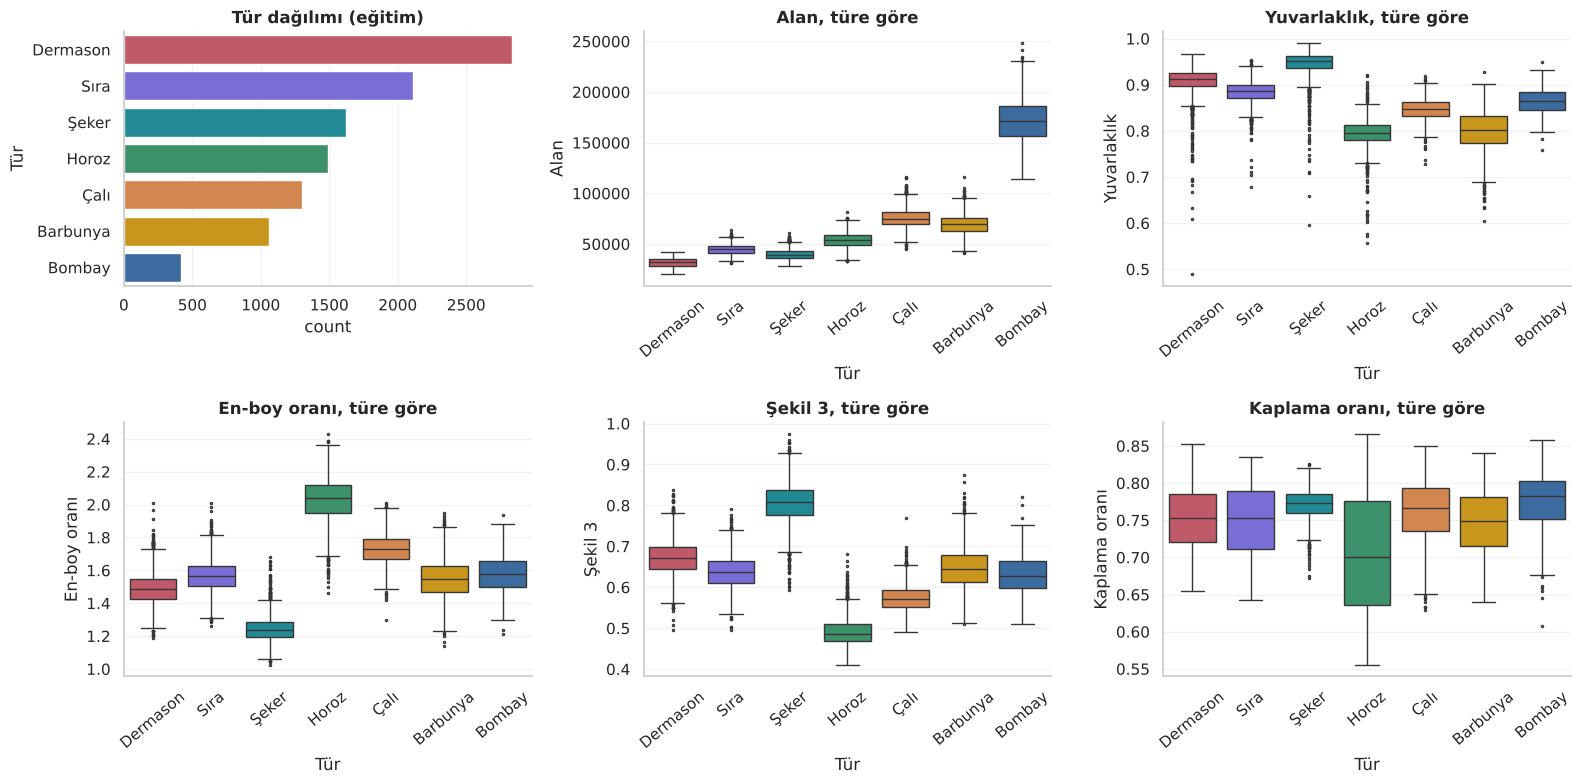

In [5]:
Etr = Xtr.rename(columns=TR_AD).copy(); Etr["Tür"] = pd.Series(ytr).map(dict(enumerate(le.classes_))).values
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
sira = Etr["Tür"].value_counts().index
sns.countplot(data=Etr, y="Tür", order=sira, palette=[SINIF_RENK[t] for t in sira], ax=ax[0, 0]); ax[0, 0].set_title("Tür dağılımı (eğitim)")
for a, kol in zip(ax.flat[1:], ["Alan", "Yuvarlaklık", "En-boy oranı", "Şekil 3", "Kaplama oranı"]):
    sns.boxplot(data=Etr, x="Tür", y=kol, order=sira, palette=[SINIF_RENK[t] for t in sira], ax=a, fliersize=1.5)
    a.set_title(f"{kol}, türe göre"); a.tick_params(axis="x", rotation=40)
fig.tight_layout(); kaydet(fig, "01_eda_genel"); plt.show()

### 🔗 4.3 · Korelasyon Duvarı: PCA'nın Var Olma Sebebi

Ölçülerin birbirine ne kadar bağlı olduğuna bakalım. **Mutlak korelasyonu 0,9'dan büyük** çiftleri sayacağız ve korelasyon matrisinin **koşul sayısına** (en büyük / en küçük özdeğer) bakacağız: büyük koşul sayısı = ölçüler birbirinin kopyası gibi.

**Okuma:** 256 ölçü çiftinin **21**'inde |r| > 0,9. Korelasyon matrisinin koşul sayısı **4,925,980** → ölçüler ciddi biçimde **tekrar eden bilgi** taşıyor; PCA tam bu durumda iş görür.

💾 Kaydedildi → outputs/figures/02_iliskiler.png


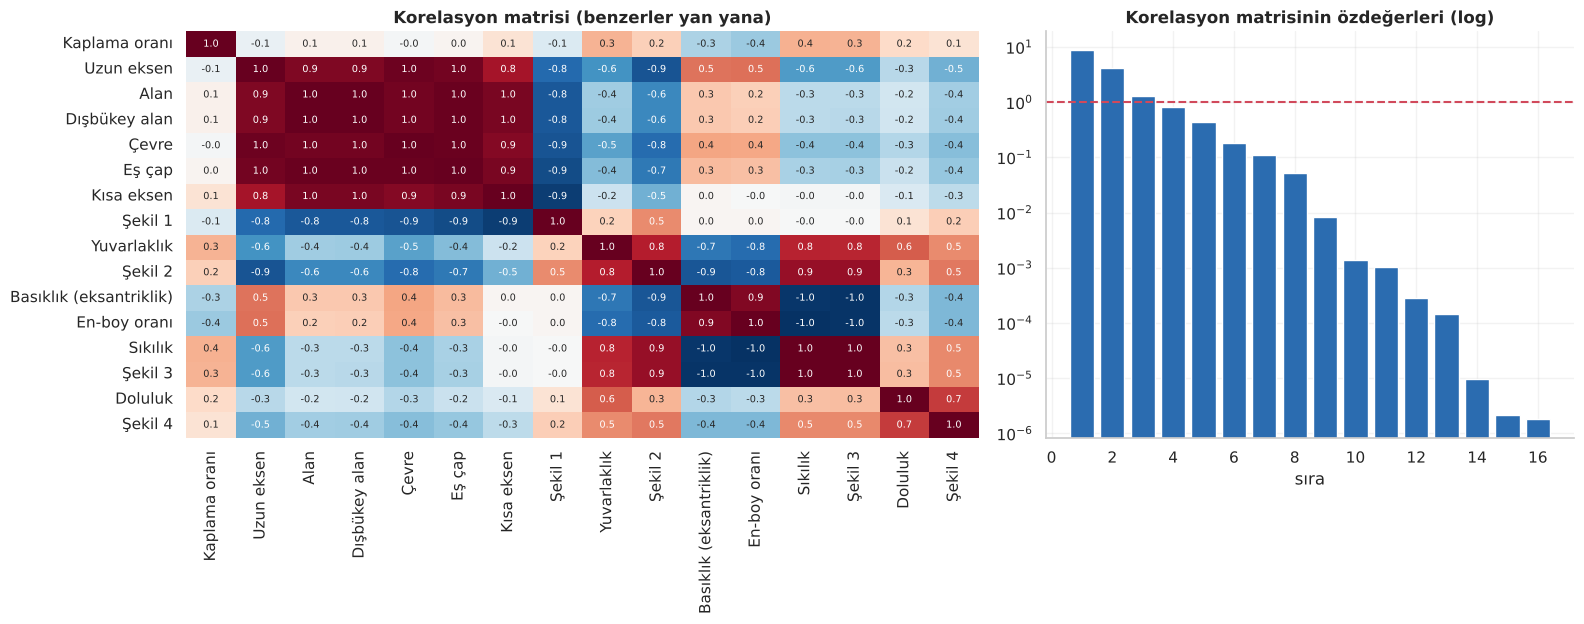

,Çevre,Dışbükey alan,Eş çap,Alan,Uzun eksen,Şekil 2,Şekil 1,Kısa eksen,Sıkılık,Şekil 3,En-boy oranı,Basıklık (eksantriklik),Yuvarlaklık,Şekil 4,Doluluk,Kaplama oranı
Karşılıklı bilgi,1.057,1.039,1.032,1.032,0.991,0.948,0.933,0.919,0.826,0.825,0.81,0.81,0.798,0.36,0.238,0.198


📄 Rapor → outputs/reports/03_karsilikli_bilgi.csv


In [6]:
kor = Xtr.rename(columns=TR_AD).corr()
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform
sira_k = leaves_list(linkage(squareform(1 - kor.abs().to_numpy(), checks=False), "average"))     # benzer ölçüler yan yana
kor_s = kor.iloc[sira_k, sira_k]
fig, ax = plt.subplots(1, 2, figsize=(16, 6.4), gridspec_kw={"width_ratios": [1.5, 1]})
sns.heatmap(kor_s, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f", annot_kws={"size": 7}, ax=ax[0], cbar=False)
ax[0].set_title("Korelasyon matrisi (benzerler yan yana)"); ax[0].grid(False)

ust = kor.where(np.triu(np.ones(kor.shape), 1).astype(bool)).stack()
yuksek = (ust.abs() > 0.9).sum()
ozdeger = np.linalg.eigvalsh(kor.to_numpy()); kosul = ozdeger.max() / ozdeger.min()
display(Markdown(f"**Okuma:** {len(ust)} ölçü çiftinin **{yuksek}**'inde |r| > 0,9. Korelasyon matrisinin koşul sayısı **{kosul:,.0f}** → ölçüler ciddi biçimde **tekrar eden bilgi** taşıyor; PCA tam bu durumda iş görür."))
ozd = np.sort(ozdeger)[::-1]
ax[1].bar(range(1, 17), ozd, color=RENK["mavi"]); ax[1].set_yscale("log"); ax[1].set_title("Korelasyon matrisinin özdeğerleri (log)")
ax[1].set_xlabel("sıra"); ax[1].axhline(1, color=RENK["pembe"], ls="--")
fig.tight_layout(); kaydet(fig, "02_iliskiler"); plt.show()

# Hedefle ilişki: karşılıklı bilgi (doğrusal olmayanı da yakalar)
mi = pd.Series(mutual_info_classif(Xtr, ytr, random_state=RANDOM_STATE), index=[TR_AD[o] for o in OZELLIKLER]).sort_values(ascending=False)
display(mi.round(3).to_frame("Karşılıklı bilgi").T)
rapor_kaydet(mi.to_frame("karsilikli_bilgi"), "03_karsilikli_bilgi")

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Isı haritasında **alan, çevre, eksenler, dışbükey alan ve eş çap** koyu kırmızı bir **blok** oluşturuyor: hepsi aslında "fasulye ne kadar büyük?" sorusunun farklı ifadesi. Şekil faktörleri ters yönde koyu mavi bir blok. **16 ölçünün gerçek bilgi miktarı 16'dan çok daha az**; PCA'nın işi bu fazlalığı sıkıştırmaktır.

</td></tr></table>

<a id="p5"></a>

<p align="center">
  <img src="assets/proje_05.svg" width="100%" alt="Bölüm 5">
</p>

### 🧪 5.1 · İki Sızıntı Deneyi

Bu bölümde iki soruyu **eğitim verisi içinde** (test'e dokunmadan) ölçüyoruz:

1. **Kopya sızıntısı:** Kopya satırlar bırakılırsa test iyimser olur mu?
2. **PCA sızıntısı:** PCA'yı bölmeden önce **tüm veride** öğrenmek skoru şişirir mi?

<p align="center">
  <img src="assets/diyagram_sizinti.svg" width="100%" alt="PCA sızıntısı">
</p>

In [7]:
# ── Deney 1: Kopya satırlar ──────────────────────────────────
# 1-en yakın komşu kopyaları "ezberler": aynı fasulye hem eğitimde hem testte varsa fazladan doğru bilir.
sonuc_k = []
for ad, veri in [("Kopyalar DURUYOR (ham 13.611)", ham), ("Kopyalar ÇIKARILDI (13.543)", ham.drop_duplicates())]:
    Xv = veri[OZELLIKLER]; yv = LabelEncoder().fit_transform(veri[HEDEF])
    skorlar = []
    for tohum in range(10):                                   # 10 farklı rastgele bölme
        a, b, c, e = train_test_split(Xv, yv, test_size=0.25, stratify=yv, random_state=tohum)
        m = Pipeline([("olcek", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=1))]).fit(a, c)
        skorlar.append(f1_score(e, m.predict(b), average="macro"))
    sonuc_k.append({"Düzen": ad, "1-NN makro F1 (ort)": np.mean(skorlar), "Std": np.std(skorlar)})
kopya_tablo = pd.DataFrame(sonuc_k).set_index("Düzen"); display(kopya_tablo.round(4))
rapor_kaydet(kopya_tablo, "04_kopya_deneyi")

,1-NN makro F1 (ort),Std
Düzen,,
Kopyalar DURUYOR (ham 13.611),0.9221,0.0027
Kopyalar ÇIKARILDI (13.543),0.9216,0.0028


📄 Rapor → outputs/reports/04_kopya_deneyi.csv


,Sızıntılı,Sızıntısız,Fark,Fark_std
Model,,,,
Lojistik,0.8910,0.8910,-0.0000,0.0009
kNN,0.8888,0.8883,0.0005,0.0012


📄 Rapor → outputs/reports/05_pca_sizintisi.csv
💾 Kaydedildi → outputs/figures/03_sizinti_deneyleri.png


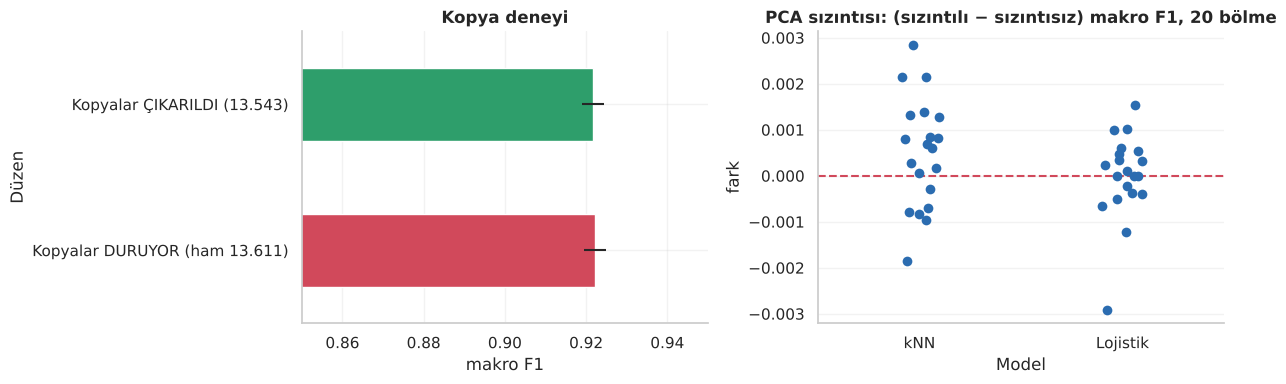

In [8]:
# ── Deney 2: PCA'yı bölmeden önce öğrenmek ───────────────────
# Yalnızca EĞİTİM verisi içinde: 20 kez iç-eğitim / iç-doğrulama bölmesi.
satir = []
for tohum in range(20):
    a, b, c, e = train_test_split(Xtr, ytr, test_size=0.25, stratify=ytr, random_state=tohum)
    for ad, model in [("kNN", KNeighborsClassifier()), ("Lojistik", LogisticRegression(max_iter=2000))]:
        # (a) YANLIŞ: ölçekleme+PCA iç-eğitim ve iç-doğrulamanın TOPLAMINDA öğrenilir
        tumu = pd.concat([a, b]); ol = StandardScaler().fit(tumu); pc = PCA(4).fit(ol.transform(tumu))
        Za = pc.transform(ol.transform(a)); Zb = pc.transform(ol.transform(b))
        s_yanlis = f1_score(e, clone(model).fit(Za, c).predict(Zb), average="macro")
        # (b) DOĞRU: yalnızca iç-eğitimde öğrenilir
        mm = Pipeline([("o", StandardScaler()), ("p", PCA(4)), ("m", clone(model))]).fit(a, c)
        s_dogru = f1_score(e, mm.predict(b), average="macro")
        satir.append({"Model": ad, "Sızıntılı": s_yanlis, "Sızıntısız": s_dogru})
sz = pd.DataFrame(satir); sz["Fark"] = sz["Sızıntılı"] - sz["Sızıntısız"]
sz_ozet = sz.groupby("Model").agg(Sızıntılı=("Sızıntılı", "mean"), Sızıntısız=("Sızıntısız", "mean"), Fark=("Fark", "mean"), Fark_std=("Fark", "std"))
display(sz_ozet.round(4))
rapor_kaydet(sz_ozet, "05_pca_sizintisi")

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4))
kopya_tablo["1-NN makro F1 (ort)"].plot.barh(ax=ax[0], color=[RENK["pembe"], RENK["yesil"]], xerr=kopya_tablo["Std"]); ax[0].set_xlim(.85, .95)
ax[0].set_title("Kopya deneyi"); ax[0].set_xlabel("makro F1")
sns.stripplot(data=sz, x="Model", y="Fark", ax=ax[1], color=RENK["mavi"], size=7); ax[1].axhline(0, color=RENK["pembe"], ls="--")
ax[1].set_title("PCA sızıntısı: (sızıntılı − sızıntısız) makro F1, 20 bölme"); ax[1].set_ylabel("fark")
fig.tight_layout(); kaydet(fig, "03_sizinti_deneyleri"); plt.show()

In [9]:
fk = kopya_tablo["1-NN makro F1 (ort)"]
display(Markdown(f"**Okuma:** kopyalar dururken 1-NN makro F1 = **{fk.iloc[0]:.4f}**, çıkarılınca **{fk.iloc[1]:.4f}** (fark {fk.iloc[0]-fk.iloc[1]:+.4f}). "
                 f"PCA sızıntısının ortalama etkisi kNN için **{sz_ozet.loc['kNN','Fark']:+.4f}**, lojistik için **{sz_ozet.loc['Lojistik','Fark']:+.4f}** "
                 f"(20 bölmenin standart sapması ≈ {sz['Fark'].std():.4f}). Etki, bölmeler arası dalgalanmaya kıyasla ne kadar büyük? Yukarıdaki grafiğe bakın."))

**Okuma:** kopyalar dururken 1-NN makro F1 = **0.9221**, çıkarılınca **0.9216** (fark +0.0005). PCA sızıntısının ortalama etkisi kNN için **+0.0005**, lojistik için **-0.0000** (20 bölmenin standart sapması ≈ 0.0011). Etki, bölmeler arası dalgalanmaya kıyasla ne kadar büyük? Yukarıdaki grafiğe bakın.

<table><tr><td>

<img src="assets/etiket_not.svg" height="34" alt="Not">

PCA **etiketi kullanmaz** ve burada 10 bin satır var; bu yüzden sızıntının etkisi **küçük** ya da gürültü düzeyinde olabilir. Bu, "sızıntı sorun değil" demek **değildir**: küçük örneklemde, çok sütunlu veride ya da hedefle birlikte kullanılan seçicilerde etki büyür. **Kural değişmez:** ölçekleyici ve PCA her zaman boru hattının içinde, yalnızca eğitim katında öğrenilir.

</td></tr></table>

<a id="p6"></a>

<p align="center">
  <img src="assets/proje_06.svg" width="100%" alt="Bölüm 6">
</p>

### 🔬 6.1 · Dirsek, Birikimli Varyans ve Kurallar (yalnızca eğitim)

Kural,Kaiser (λ>1),Paralel analiz,%95 varyans (SEÇİLEN),%99 varyans
k,3,3,4,7


**Yarış için k = 4** (kural: %95). İlk 2 bileşen %81.9, ilk 4 bileşen %95.0, ilk 7 bileşen %99.6 varyansı taşıyor.

💾 Kaydedildi → outputs/figures/04_pca_dirsek.png


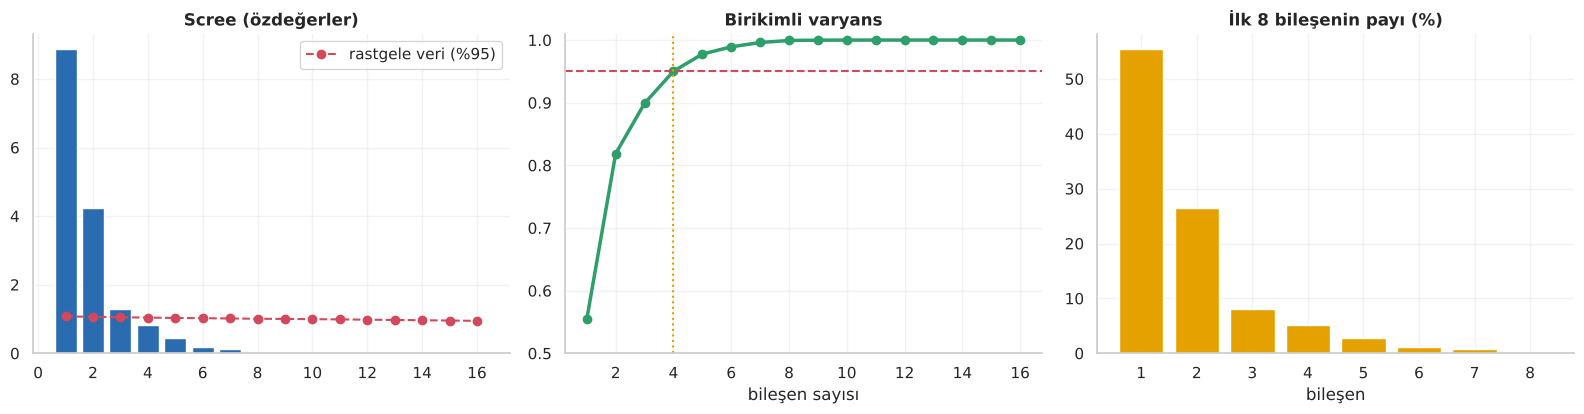

📄 Rapor → outputs/reports/06_pca_ozdeger.csv


In [10]:
olcek_tr = StandardScaler().fit(Xtr); Ztr = olcek_tr.transform(Xtr)
pca_tr = PCA().fit(Ztr)
lam = pca_tr.explained_variance_; oran = pca_tr.explained_variance_ratio_; kum = np.cumsum(oran); p = len(lam)

K_95 = int(np.argmax(kum >= 0.95) + 1)           # ÖNCEDEN YAZILMIŞ KURAL: %95 → yarışın k değeri
K_99 = int(np.argmax(kum >= 0.99) + 1)
kaiser = int((lam > 1).sum())
rng = np.random.default_rng(RANDOM_STATE); rast = []
for _ in range(50):                               # paralel analiz: her sütunu bağımsız karıştır
    Zr = np.column_stack([rng.permutation(Ztr[:, j]) for j in range(p)]); rast.append(PCA().fit(Zr).explained_variance_)
esik = np.percentile(rast, 95, axis=0); paralel = int(np.argmax(lam <= esik))
kurallar = pd.DataFrame({"Kural": ["Kaiser (λ>1)", "Paralel analiz", "%95 varyans (SEÇİLEN)", "%99 varyans"],
                         "k": [kaiser, paralel, K_95, K_99]}).set_index("Kural")
display(kurallar.T)
display(Markdown(f"**Yarış için k = {K_95}** (kural: %95). İlk 2 bileşen %{kum[1]*100:.1f}, ilk {K_95} bileşen %{kum[K_95-1]*100:.1f}, ilk {K_99} bileşen %{kum[K_99-1]*100:.1f} varyansı taşıyor."))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
xs = np.arange(1, p + 1)
ax[0].bar(xs, lam, color=RENK["mavi"]); ax[0].plot(xs, esik, "o--", color=RENK["pembe"], label="rastgele veri (%95)"); ax[0].set_title("Scree (özdeğerler)"); ax[0].legend()
ax[1].plot(xs, kum, "o-", color=RENK["yesil"], lw=2.5); ax[1].axhline(.95, color=RENK["pembe"], ls="--"); ax[1].axvline(K_95, color=RENK["altin"], ls=":")
ax[1].set_title("Birikimli varyans"); ax[1].set_xlabel("bileşen sayısı"); ax[1].set_ylim(.5, 1.01)
ax[2].bar(xs[:8], oran[:8] * 100, color=RENK["altin"]); ax[2].set_title("İlk 8 bileşenin payı (%)"); ax[2].set_xlabel("bileşen")
fig.tight_layout(); kaydet(fig, "04_pca_dirsek"); plt.show()
rapor_kaydet(pd.DataFrame({"ozdeger": lam, "oran": oran, "birikimli": kum}, index=xs), "06_pca_ozdeger")

### 🗺️ 6.2 · Yükler, Harita ve Çift Grafik (Biplot)

**Yük (loading):** bir bileşenin hangi ölçüden ne kadar "aldığı". Biplot'ta oklar ölçüleri, noktalar fasulyeleri gösterir.

💾 Kaydedildi → outputs/figures/05_pca_harita_biplot.png


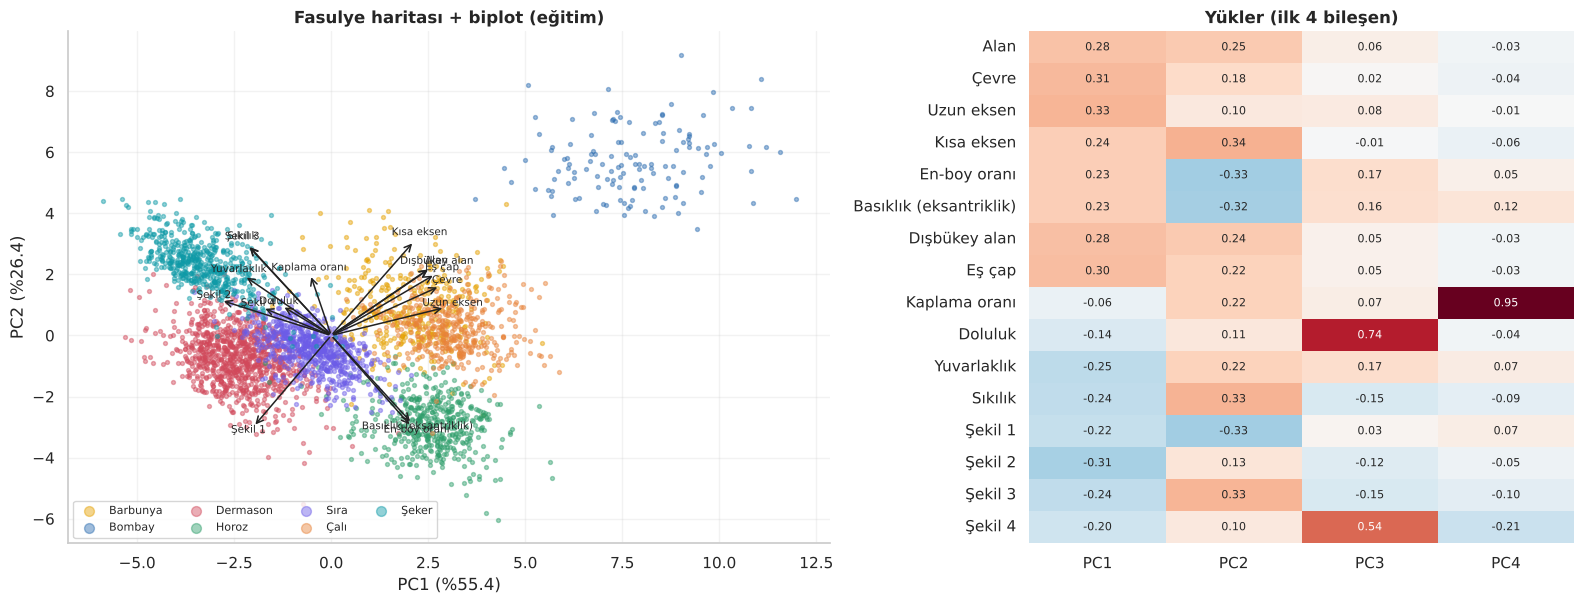

📄 Rapor → outputs/reports/07_pca_yukler.csv


In [11]:
pca4 = PCA(n_components=4).fit(Ztr); S4 = pca4.transform(Ztr)
yuk = pd.DataFrame(pca4.components_.T, index=[TR_AD[o] for o in OZELLIKLER], columns=[f"PC{i+1}" for i in range(4)])
tur_tr = pd.Series(ytr).map(dict(enumerate(le.classes_))).to_numpy()
idx = np.random.default_rng(RANDOM_STATE).choice(len(S4), 3500, replace=False)

fig, ax = plt.subplots(1, 2, figsize=(16, 6.2), gridspec_kw={"width_ratios": [1.4, 1]})
for t in SINIFLAR:
    m = tur_tr[idx] == t; ax[0].scatter(S4[idx][m, 0], S4[idx][m, 1], s=8, alpha=.45, color=SINIF_RENK[t], label=t)
for ad, (a, b) in zip(yuk.index, yuk[["PC1", "PC2"]].to_numpy()):                  # biplot okları
    ax[0].annotate("", xy=(a * 9, b * 9), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="#222", lw=1.1))
    ax[0].text(a * 9.6, b * 9.6, ad, fontsize=7.5, ha="center")
ax[0].set_xlabel(f"PC1 (%{oran[0]*100:.1f})"); ax[0].set_ylabel(f"PC2 (%{oran[1]*100:.1f})")
ax[0].set_title("Fasulye haritası + biplot (eğitim)"); ax[0].legend(markerscale=2.5, ncol=4, loc="lower left", fontsize=8)
sns.heatmap(yuk, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax[1], cbar=False, annot_kws={"size": 8}); ax[1].grid(False)
ax[1].set_title("Yükler (ilk 4 bileşen)")
fig.tight_layout(); kaydet(fig, "05_pca_harita_biplot"); plt.show()
rapor_kaydet(yuk, "07_pca_yukler")

### 🎞️ 6.3 · Üç Boyutlu Fasulye Bulutu (Animasyon)

İlk **üç bileşenle** (%90'e yakın varyans) bulut dönerken türlerin nasıl ayrıştığına bakın.

🎞️ Animasyon → outputs/figures/06_pca_3b_donus.gif


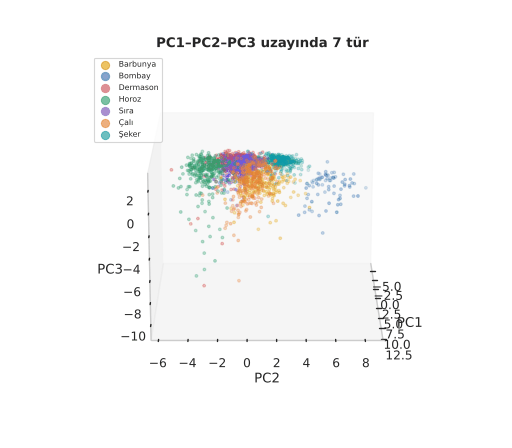

In [12]:
idx3 = idx[:2200]
def kare(i, fig):
    ax = fig.add_subplot(1, 1, 1, projection="3d")
    for t in SINIFLAR:
        m = tur_tr[idx3] == t
        ax.scatter(S4[idx3][m, 0], S4[idx3][m, 1], S4[idx3][m, 2], s=6, alpha=.6, color=SINIF_RENK[t], label=t)
    ax.view_init(elev=18, azim=i * 8); ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("PC3")
    ax.set_title("PC1–PC2–PC3 uzayında 7 tür"); ax.grid(False)
    if i == 0: ax.legend(markerscale=3, loc="upper left", fontsize=7)
gif_kaydet(kare, 45, "06_pca_3b_donus", figsize=(6.4, 5.6), fps=10)

### 🧩 6.4 · Her Ölçünün Ne Kadarı Korunuyor? (k = k)

💾 Kaydedildi → outputs/figures/06_olcu_basina_korunma.png


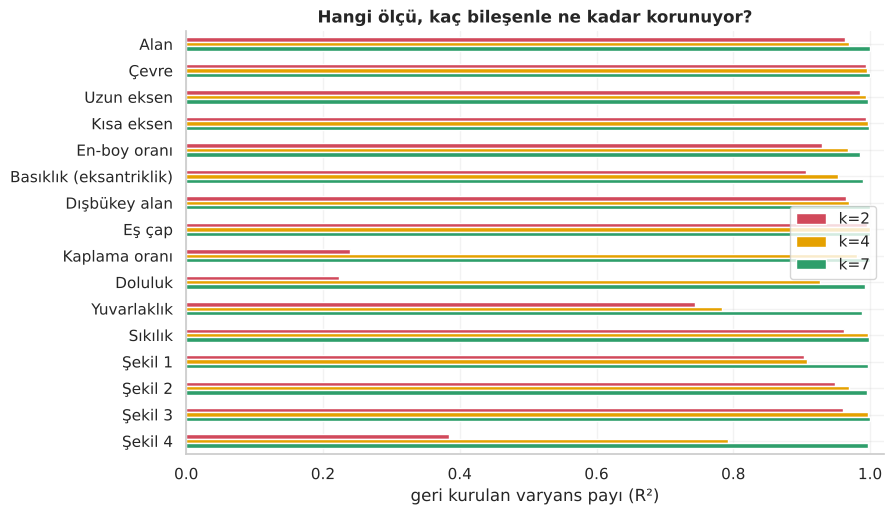

📄 Rapor → outputs/reports/08_olcu_basina_korunma.csv


**Okuma:** k=4 ile **en az korunan** ölçüler: **Yuvarlaklık** (R²=0.78), **Şekil 4** (R²=0.79), **Şekil 1** (R²=0.91). Bunlar bileşenlerde **az yer tutan, kendine özgü** ölçülerdir; sınıflandırma için kritikse PCA'nın kaybettiği şey tam budur.

In [13]:
# Her ölçünün k bileşenle ne kadarı (R²) geri kurulabiliyor? Düşük R² = o ölçüye özgü bilgi bileşenlerde yok.
r2 = {}
for k in [2, K_95, K_99]:
    pk = PCA(k).fit(Ztr); geri = pk.inverse_transform(pk.transform(Ztr))
    r2[f"k={k}"] = 1 - ((Ztr - geri) ** 2).sum(0) / (Ztr ** 2).sum(0)
r2 = pd.DataFrame(r2, index=[TR_AD[o] for o in OZELLIKLER])
fig, ax = plt.subplots(figsize=(9, 5.5)); r2.plot.barh(ax=ax, color=[RENK["pembe"], RENK["altin"], RENK["yesil"]]); ax.invert_yaxis()
ax.set_xlabel("geri kurulan varyans payı (R²)"); ax.set_title("Hangi ölçü, kaç bileşenle ne kadar korunuyor?"); ax.set_xlim(0, 1.02)
kaydet(fig, "06_olcu_basina_korunma"); plt.show()
rapor_kaydet(r2, "08_olcu_basina_korunma")
enaz = r2[f"k={K_95}"].sort_values().head(3)
display(Markdown(f"**Okuma:** k={K_95} ile **en az korunan** ölçüler: " + ", ".join(f"**{a}** (R²={b:.2f})" for a, b in enaz.items()) + ". Bunlar bileşenlerde **az yer tutan, kendine özgü** ölçülerdir; sınıflandırma için kritikse PCA'nın kaybettiği şey tam budur."))

<a id="p7"></a>

<p align="center">
  <img src="assets/proje_07.svg" width="100%" alt="Bölüm 7">
</p>

### 🏁 7.1 · Yarışçılar: 27 Algoritma + Taban

Aynı eğitim verisi, aynı 5 kat. Her algoritma **iki dünyada** yarışır:

- **Ham:** `StandardScaler → model` (16 ölçü)
- **PCA:** `StandardScaler → PCA(k) → model` (k = önceden seçilen kural)

Hem ölçekleyici hem PCA **her katta yalnızca eğitim kısmında öğrenilir** (sızıntısız boru hattı). Ağaç ailesi ölçeklemeye ihtiyaç duymaz; yine de iki dünyayı **adil** kılmak için aynı adımları kullanıyoruz.

In [14]:
RS = RANDOM_STATE
def modeller():
    """(aile, model) sözlüğü. Her model yalnızca bir iş parçacığı kullanır; paralellik katlar arasında sağlanır."""
    rf_k = lambda n: RandomForestClassifier(n_estimators=n, n_jobs=1, random_state=RS)
    return {
        "Taban (en sık sınıf)":       ("Taban", DummyClassifier(strategy="most_frequent")),
        "Lojistik regresyon":         ("Doğrusal", LogisticRegression(max_iter=3000, random_state=RS)),
        "Ridge sınıflandırıcı":       ("Doğrusal", RidgeClassifier(random_state=RS)),
        "Doğrusal ayırtaç (LDA)":     ("Doğrusal", LinearDiscriminantAnalysis()),
        "SGD (log-loss)":             ("Doğrusal", SGDClassifier(loss="log_loss", max_iter=2000, random_state=RS)),
        "Perceptron":                 ("Doğrusal", Perceptron(random_state=RS)),
        "Pasif-agresif":              ("Doğrusal", PassiveAggressiveClassifier(random_state=RS)),
        "Doğrusal SVM":               ("Doğrusal", LinearSVC(max_iter=5000, dual="auto", random_state=RS)),
        "Gauss naive Bayes":          ("Mesafe/olasılık", GaussianNB()),
        "Karesel ayırtaç (QDA)":      ("Mesafe/olasılık", QuadraticDiscriminantAnalysis(reg_param=0.01)),
        "k-en yakın komşu":           ("Mesafe/olasılık", KNeighborsClassifier(n_neighbors=7)),
        "En yakın merkez":            ("Mesafe/olasılık", NearestCentroid()),
        "SVM (RBF)":                  ("Çekirdek", SVC(kernel="rbf", random_state=RS)),
        "SVM (polinom)":              ("Çekirdek", SVC(kernel="poly", degree=3, random_state=RS)),
        "Karar ağacı":                ("Ağaç", DecisionTreeClassifier(random_state=RS)),
        "Ekstra ağaç (tek)":          ("Ağaç", ExtraTreeClassifier(random_state=RS)),
        "Rastgele orman":             ("Topluluk", rf_k(200)),
        "Ekstra ağaçlar":             ("Topluluk", ExtraTreesClassifier(n_estimators=200, n_jobs=1, random_state=RS)),
        "Bagging (ağaç)":             ("Topluluk", BaggingClassifier(DecisionTreeClassifier(), n_estimators=50, n_jobs=1, random_state=RS)),
        "AdaBoost":                   ("Boosting", AdaBoostClassifier(n_estimators=100, random_state=RS)),
        "Gradient Boosting":          ("Boosting", GradientBoostingClassifier(n_estimators=100, random_state=RS)),
        "HistGradientBoosting":       ("Boosting", HistGradientBoostingClassifier(max_iter=200, random_state=RS)),
        "XGBoost":                    ("Boosting", XGBClassifier(n_estimators=200, n_jobs=1, random_state=RS, verbosity=0)),
        "LightGBM":                   ("Boosting", LGBMClassifier(n_estimators=200, n_jobs=1, random_state=RS, verbosity=-1)),
        "CatBoost":                   ("Boosting", CatBoostClassifier(iterations=200, thread_count=1, random_seed=RS, verbose=0, allow_writing_files=False)),
        "Sinir ağı (MLP)":            ("Sinir ağı", MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, early_stopping=True, random_state=RS)),
        "Oylama (yumuşak)":           ("Topluluk", VotingClassifier([("lr", LogisticRegression(max_iter=3000)), ("knn", KNeighborsClassifier(7)),
                                                                      ("rf", rf_k(100)), ("lgb", LGBMClassifier(n_estimators=100, n_jobs=1, random_state=RS, verbosity=-1))], voting="soft")),
        "Yığın (stacking)":           ("Topluluk", StackingClassifier([("lr", LogisticRegression(max_iter=3000)), ("knn", KNeighborsClassifier(7)), ("rf", rf_k(100))],
                                                                       final_estimator=LogisticRegression(max_iter=3000), cv=3)),
    }
YARISCI = modeller()
AILE = {a: f for a, (f, _) in YARISCI.items()}
print(f"Yarışçı sayısı: {len(YARISCI) - 1} algoritma + 1 taban")
print(pd.Series(AILE).value_counts().rename("algoritma sayısı").to_frame().T.to_string())

def boru(model, pca_k=None):
    """Sızıntısız boru hattı: ölçekle → (PCA) → model."""
    adimlar = [("olcek", StandardScaler())]
    if pca_k: adimlar.append(("pca", PCA(n_components=pca_k, random_state=RS)))
    return Pipeline(adimlar + [("model", clone(model))])

def tek_kat(ad, gor, tr, va, X, y):
    """Bir algoritmanın tek katını koşar; süreleri ve ölçütleri döndürür."""
    k = K_95 if gor == "PCA" else None
    m = boru(YARISCI[ad][1], k)
    t0 = time.perf_counter(); m.fit(X.iloc[tr], y[tr]); egitim = time.perf_counter() - t0
    t0 = time.perf_counter(); tah = m.predict(X.iloc[va]); tahmin = time.perf_counter() - t0
    s = {"Algoritma": ad, "Görünüm": gor, "Doğruluk": accuracy_score(y[va], tah), "Makro F1": f1_score(y[va], tah, average="macro"),
         "Dengeli doğruluk": balanced_accuracy_score(y[va], tah), "Eğitim sn": egitim, "Tahmin sn": tahmin, "Log-loss": np.nan}
    if hasattr(m, "predict_proba"):
        try: s["Log-loss"] = log_loss(y[va], m.predict_proba(X.iloc[va]), labels=list(range(7)))
        except Exception: pass
    return s

Yarışçı sayısı: 27 algoritma + 1 taban
                  Doğrusal  Boosting  Topluluk  Mesafe/olasılık  Çekirdek  Ağaç  Taban  Sinir ağı
algoritma sayısı         7         6         5                4         2     2      1          1


### 🏎️ 7.2 · Yarışı Koşalım

28 yarışçı × 2 görünüm × 5 kat = **280 model eğitimi**; 4 işçiyle paralel koşuyor. (Bu hücre birkaç dakika sürer.)

In [15]:
t0 = time.perf_counter()
katlar = list(CV_ANA.split(Xtr, ytr))
isler = [(ad, gor, i) for ad in YARISCI for gor in ["Ham", "PCA"] for i in range(5)]
cikti = Parallel(n_jobs=N_JOBS, verbose=0)(delayed(tek_kat)(ad, gor, katlar[i][0], katlar[i][1], Xtr, ytr) for ad, gor, i in isler)
yaris_uzun = pd.DataFrame(cikti); yaris_uzun["Aile"] = yaris_uzun["Algoritma"].map(AILE)
print(f"⏱️ Toplam yarış süresi: {time.perf_counter()-t0:.0f} sn")

olc = ["Doğruluk", "Makro F1", "Dengeli doğruluk", "Log-loss", "Eğitim sn", "Tahmin sn"]
ozet = yaris_uzun.groupby(["Algoritma", "Görünüm"])[olc].mean().unstack("Görünüm")
yaris = pd.DataFrame({
    "Aile": pd.Series(AILE),
    "Ham F1": ozet[("Makro F1", "Ham")], "PCA F1": ozet[("Makro F1", "PCA")],
    "Ham doğruluk": ozet[("Doğruluk", "Ham")], "PCA doğruluk": ozet[("Doğruluk", "PCA")],
    "Ham log-loss": ozet[("Log-loss", "Ham")], "PCA log-loss": ozet[("Log-loss", "PCA")],
    "Ham eğitim sn": ozet[("Eğitim sn", "Ham")], "PCA eğitim sn": ozet[("Eğitim sn", "PCA")],
})
yaris["Δ F1 (PCA−Ham)"] = yaris["PCA F1"] - yaris["Ham F1"]
yaris = yaris.sort_values("Ham F1", ascending=False)
yaris.insert(0, "Sıra (ham)", range(1, len(yaris) + 1))
display(yaris.round(4))
rapor_kaydet(yaris, "09_yaris_ham_pca"); rapor_kaydet(yaris_uzun, "10_yaris_kat_kat", index=False)

⏱️ Toplam yarış süresi: 117 sn


,Sıra (ham),Aile,Ham F1,PCA F1,Ham doğruluk,PCA doğruluk,Ham log-loss,PCA log-loss,Ham eğitim sn,PCA eğitim sn,Δ F1 (PCA−Ham)
Oylama (yumuşak),1,Topluluk,0.9424,0.8969,0.9304,0.8952,0.1934,0.2817,3.3473,1.7931,-0.0455
SVM (RBF),2,Çekirdek,0.9418,0.8982,0.9300,0.8964,NaN,NaN,0.2437,0.2776,-0.0436
Yığın (stacking),3,Topluluk,0.9416,0.8981,0.9296,0.8964,0.2167,0.2998,6.9937,3.9192,-0.0435
LightGBM,4,Boosting,0.9404,0.8863,0.9281,0.8852,0.3675,0.4466,2.4969,1.0861,-0.0541
HistGradientBoosting,5,Boosting,0.9396,0.8885,0.9270,0.8865,0.3959,0.4729,2.9735,1.8806,-0.0511
XGBoost,6,Boosting,0.9386,0.8854,0.9263,0.8835,0.2820,0.4063,1.7001,0.8961,-0.0532
CatBoost,7,Boosting,0.9384,0.8929,0.9268,0.8918,0.2052,0.2945,4.8213,1.6524,-0.0455
Lojistik regresyon,8,Doğrusal,0.9372,0.8905,0.9256,0.8891,0.2141,0.2946,0.1344,0.1155,-0.0467
Gradient Boosting,9,Boosting,0.9366,0.8958,0.9244,0.8940,0.2100,0.2985,25.9754,7.6117,-0.0408
Sinir ağı (MLP),10,Sinir ağı,0.9366,0.8954,0.9255,0.8940,0.2096,0.2818,0.7571,0.5977,-0.0412


📄 Rapor → outputs/reports/09_yaris_ham_pca.csv
📄 Rapor → outputs/reports/10_yaris_kat_kat.csv


### 📊 7.3 · Yarışın Görseli

💾 Kaydedildi → outputs/figures/07_buyuk_yaris.png


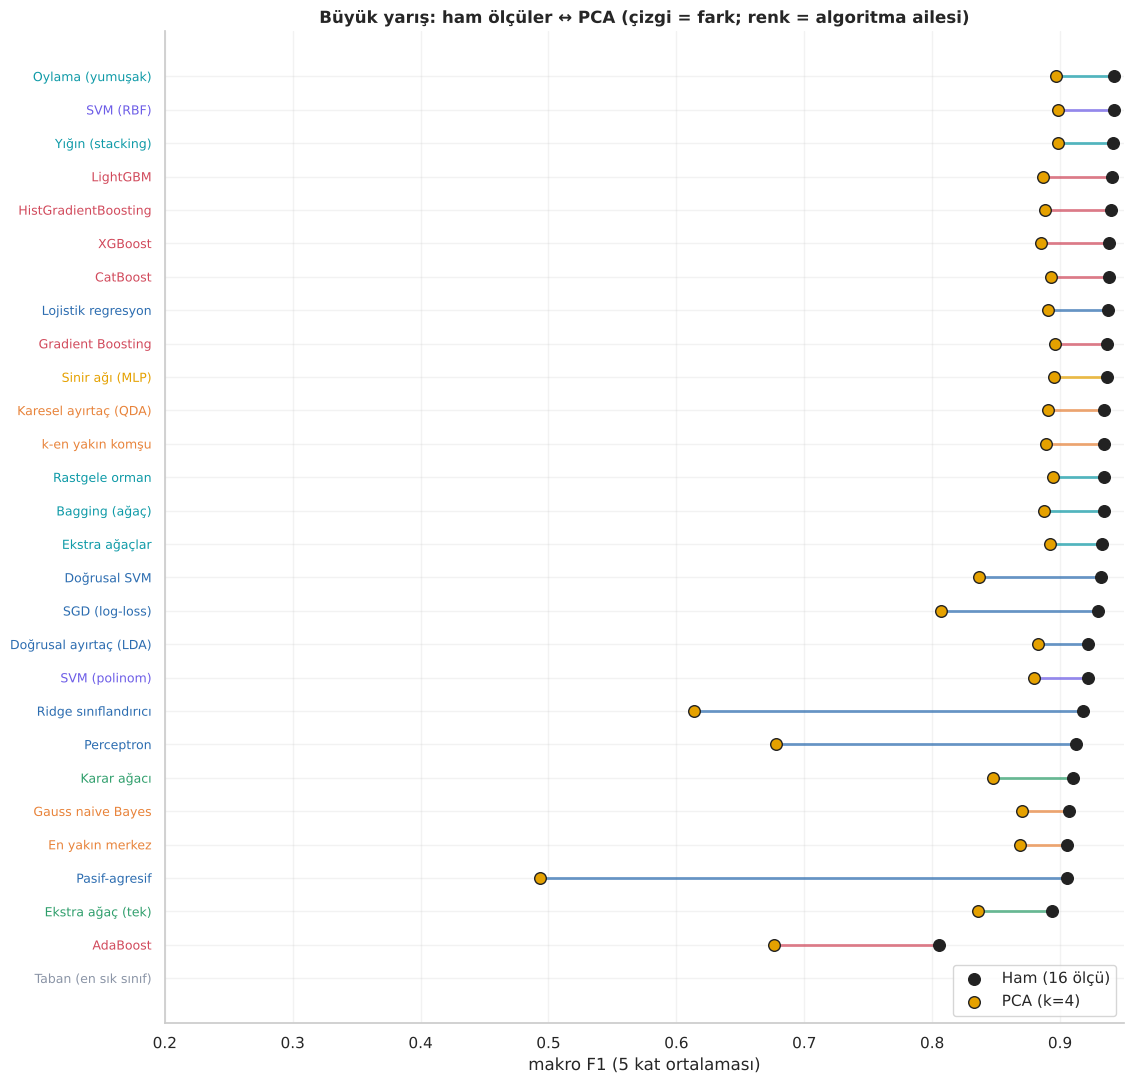

In [16]:
aile_renk = {"Taban": RENK["gri"], "Doğrusal": RENK["mavi"], "Mesafe/olasılık": RENK["turuncu"], "Çekirdek": RENK["mor"],
             "Ağaç": RENK["yesil"], "Topluluk": RENK["cyan"], "Boosting": RENK["pembe"], "Sinir ağı": RENK["altin"]}
g = yaris.iloc[::-1]
fig, ax = plt.subplots(figsize=(11.5, 11))
yy = np.arange(len(g))
for i, (ad, r) in enumerate(g.iterrows()):
    ax.plot([r["Ham F1"], r["PCA F1"]], [i, i], color=aile_renk[r["Aile"]], lw=2, alpha=.7)
ax.scatter(g["Ham F1"], yy, s=70, color="#222", zorder=3, label="Ham (16 ölçü)")
ax.scatter(g["PCA F1"], yy, s=70, color=RENK["altin"], edgecolor="#222", zorder=3, label=f"PCA (k={K_95})")
ax.set_yticks(yy); ax.set_yticklabels(g.index, fontsize=9)
for lab in ax.get_yticklabels(): lab.set_color(aile_renk[AILE[lab.get_text()]])
ax.set_xlim(0.2, 0.95); ax.set_xlabel("makro F1 (5 kat ortalaması)"); ax.legend(loc="lower right")
ax.set_title("Büyük yarış: ham ölçüler ↔ PCA (çizgi = fark; renk = algoritma ailesi)")
fig.tight_layout(); kaydet(fig, "07_buyuk_yaris"); plt.show()

In [17]:
lider = yaris.index[0]; ikinci = yaris.index[1]
n_pca_kotu = int((yaris.drop("Taban (en sık sınıf)")["Δ F1 (PCA−Ham)"] < -0.005).sum())
display(Markdown(f"**Okuma:** ham dünyada lider **{lider}** (makro F1 {yaris.loc[lider,'Ham F1']:.4f}), onu **{ikinci}** ({yaris.loc[ikinci,'Ham F1']:.4f}) izliyor. "
                 f"PCA(k={K_95}) kullanınca **{n_pca_kotu} / 27** algoritma makro F1'de 0,005'ten fazla kaybediyor. "
                 f"PCA dünyasında en iyi: **{yaris['PCA F1'].idxmax()}** ({yaris['PCA F1'].max():.4f}). Taban modelin makro F1'i {yaris.loc['Taban (en sık sınıf)','Ham F1']:.3f}: yani öğrenme gerçekten bir şey öğreniyor."))

**Okuma:** ham dünyada lider **Oylama (yumuşak)** (makro F1 0.9424), onu **SVM (RBF)** (0.9418) izliyor. PCA(k=4) kullanınca **27 / 27** algoritma makro F1'de 0,005'ten fazla kaybediyor. PCA dünyasında en iyi: **SVM (RBF)** (0.8982). Taban modelin makro F1'i 0.059: yani öğrenme gerçekten bir şey öğreniyor.

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Sıralamanın **üst yarısı birbirine çok yakın**: yüzde birin onda biri farklar, sıralamayı **şans** da belirleyebilir (8.1'de ölçeceğiz). Asıl çarpıcı bulgu ise **PCA(k=4) dünyasında**: neredeyse **tüm** algoritmalar yaklaşık 4–5 puan makro F1 kaybediyor; yani %95 varyans kuralı bu veride **yetersiz kaldı**. Ridge, Perceptron ve Pasif-agresif gibi doğrusal modeller ise çok daha sert çöküyor. Olası bir neden: PCA çıktısındaki bileşenlerin **varyansları çok farklı** (PC1 ≈ 8,9, PC4 ≈ 0,8) ve bu modeller ölçek farkına duyarlı (ödev 5'te `whiten=True` ile sınayın). Bu, bir **hipotezdir**; burada test edilmedi.

</td></tr></table>

<a id="p8"></a>

<p align="center">
  <img src="assets/proje_08.svg" width="100%" alt="Bölüm 8">
</p>

### 📊 8.1 · Taze Katlarda Eşleştirilmiş Karşılaştırma

Yarış tek bir 5 katlı bölmede koşuldu; üst sıradaki 10 algoritmayı **taze 10 katta** (5×2 tekrarlı) hem ham hem PCA ile tekrar koşuyoruz ve **aynı kat üzerinde farkı** (eşleştirilmiş) alıyoruz. Fark için **bootstrap** %95 aralığı hesaplanır: aralık 0'ı kesiyorsa fark şanstan ayırt edilemez.

,Ham F1,PCA F1,Fark,%95 alt,%95 üst,Anlamlı?
Algoritma,,,,,,
Oylama (yumuşak),0.9418,0.8969,-0.0449,-0.0485,-0.0409,evet
SVM (RBF),0.9408,0.8985,-0.0423,-0.0470,-0.0372,evet
Yığın (stacking),0.9400,0.8964,-0.0435,-0.0467,-0.0400,evet
LightGBM,0.9385,0.8882,-0.0503,-0.0540,-0.0464,evet
HistGradientBoosting,0.9380,0.8868,-0.0513,-0.0540,-0.0487,evet
XGBoost,0.9375,0.8877,-0.0498,-0.0523,-0.0473,evet
CatBoost,0.9386,0.8928,-0.0458,-0.0489,-0.0419,evet
Lojistik regresyon,0.9372,0.8902,-0.0469,-0.0510,-0.0426,evet
Gradient Boosting,0.9358,0.8953,-0.0405,-0.0443,-0.0367,evet


📄 Rapor → outputs/reports/11_taze_katlar_esles.csv


💾 Kaydedildi → outputs/figures/08_pca_fark_bootstrap.png


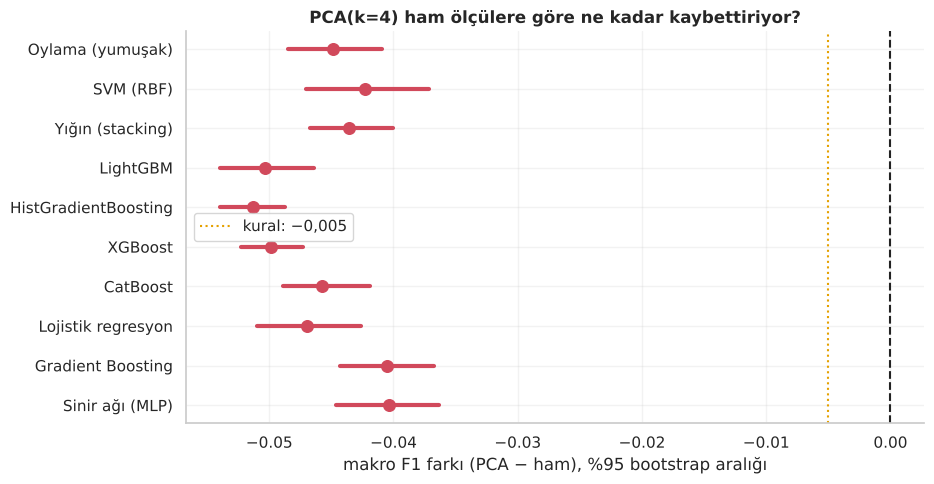

In [18]:
ust = [a for a in yaris.index if a != "Taban (en sık sınıf)"][:10]
katlar_taze = list(CV_TAZE.split(Xtr, ytr))
isler = [(ad, gor, i) for ad in ust for gor in ["Ham", "PCA"] for i in range(len(katlar_taze))]
cikti = Parallel(n_jobs=N_JOBS)(delayed(tek_kat)(ad, gor, katlar_taze[i][0], katlar_taze[i][1], Xtr, ytr) for ad, gor, i in isler)
tz = pd.DataFrame(cikti); tz["kat"] = [i for _, _, i in isler]
pv = tz.pivot_table(index=["Algoritma", "kat"], columns="Görünüm", values="Makro F1").reset_index()
pv["fark"] = pv["PCA"] - pv["Ham"]
rng = np.random.default_rng(RANDOM_STATE); satir = []
for ad in ust:
    f = pv[pv["Algoritma"] == ad]["fark"].to_numpy()
    bs = [rng.choice(f, len(f)).mean() for _ in range(4000)]
    lo, hi = np.percentile(bs, [2.5, 97.5])
    satir.append({"Algoritma": ad, "Ham F1": pv[pv["Algoritma"] == ad]["Ham"].mean(), "PCA F1": pv[pv["Algoritma"] == ad]["PCA"].mean(),
                  "Fark": f.mean(), "%95 alt": lo, "%95 üst": hi, "Anlamlı?": "evet" if (lo > 0 or hi < 0) else "hayır"})
esles = pd.DataFrame(satir).set_index("Algoritma"); display(esles.round(4))
rapor_kaydet(esles, "11_taze_katlar_esles")

fig, ax = plt.subplots(figsize=(9.5, 5))
for i, (ad, r) in enumerate(esles.iloc[::-1].iterrows()):
    c = RENK["pembe"] if r["Anlamlı?"] == "evet" and r["Fark"] < 0 else (RENK["yesil"] if r["Anlamlı?"] == "evet" else RENK["gri"])
    ax.plot([r["%95 alt"], r["%95 üst"]], [i, i], color=c, lw=3); ax.scatter([r["Fark"]], [i], s=70, color=c, zorder=3)
ax.axvline(0, color="#222", ls="--"); ax.axvline(-0.005, color=RENK["altin"], ls=":", label="kural: −0,005")
ax.set_yticks(range(len(esles))); ax.set_yticklabels(esles.index[::-1]); ax.set_xlabel("makro F1 farkı (PCA − ham), %95 bootstrap aralığı")
ax.set_title(f"PCA(k={K_95}) ham ölçülere göre ne kadar kaybettiriyor?"); ax.legend()
fig.tight_layout(); kaydet(fig, "08_pca_fark_bootstrap"); plt.show()

### ⏱️ 8.2 · Hız: PCA Gerçekten Hızlandırıyor mu?

Katlar paralel koştuğu için yarıştaki süreler gürültülüdür. Bu yüzden **tüm eğitim verisinde, art arda (paralelsiz), tek tek** süre ölçüyoruz (her model ham ve PCA için bir kez; **tek ölçüm**, mutlak sayılar makineye bağlıdır, **oranlar** anlamlıdır).

In [19]:
sure = []
for ad in YARISCI:
    if ad.startswith("Taban"): continue
    satir = {"Algoritma": ad, "Aile": AILE[ad]}
    for gor, k in [("Ham", None), ("PCA", K_95)]:
        m = boru(YARISCI[ad][1], k); t0 = time.perf_counter(); m.fit(Xtr, ytr); satir[f"{gor} eğitim sn"] = time.perf_counter() - t0
        t0 = time.perf_counter(); m.predict(Xtr.iloc[:2000]); satir[f"{gor} tahmin sn (2000)"] = time.perf_counter() - t0
    satir["Hızlanma (eğitim)"] = satir["Ham eğitim sn"] / satir["PCA eğitim sn"]
    sure.append(satir)
sure = pd.DataFrame(sure).set_index("Algoritma")
sure = sure.join(yaris[["Ham F1", "PCA F1", "Δ F1 (PCA−Ham)"]])
display(sure.sort_values("Hızlanma (eğitim)", ascending=False).round(3))
rapor_kaydet(sure, "12_sure_deneyi")

# Önceden yazılmış kural: ΔF1 ≥ −0,005 VE süre kısalması ≥ %30
sure["Kural geçti"] = (sure["Δ F1 (PCA−Ham)"] >= -0.005) & (1 - sure["PCA eğitim sn"] / sure["Ham eğitim sn"] >= 0.30)
gecen = sure.index[sure["Kural geçti"]].tolist()
display(Markdown(f"**Kural 2'yi (ΔF1 ≥ −0,005 ve eğitim süresi ≥ %30 kısalma) geçen algoritmalar ({len(gecen)}):** " + (", ".join(gecen) if gecen else "yok")))

,Aile,Ham eğitim sn,Ham tahmin sn (2000),PCA eğitim sn,PCA tahmin sn (2000),Hızlanma (eğitim),Ham F1,PCA F1,Δ F1 (PCA−Ham)
Algoritma,,,,,,,,,
Doğrusal SVM,Doğrusal,0.193,0.003,0.035,0.003,5.517,0.932,0.837,-0.095
Lojistik regresyon,Doğrusal,1.175,0.002,0.242,0.003,4.853,0.937,0.890,-0.047
Karar ağacı,Ağaç,0.178,0.002,0.037,0.002,4.846,0.910,0.848,-0.062
Bagging (ağaç),Topluluk,5.056,0.017,1.179,0.015,4.288,0.934,0.888,-0.047
Gradient Boosting,Boosting,32.665,0.014,9.657,0.018,3.382,0.937,0.896,-0.041
CatBoost,Boosting,5.987,0.004,1.861,0.005,3.217,0.938,0.893,-0.046
AdaBoost,Boosting,1.931,0.022,0.656,0.024,2.943,0.806,0.676,-0.129
Oylama (yumuşak),Topluluk,6.055,0.129,2.308,0.115,2.623,0.942,0.897,-0.045
Pasif-agresif,Doğrusal,0.089,0.003,0.040,0.003,2.236,0.905,0.493,-0.412


📄 Rapor → outputs/reports/12_sure_deneyi.csv


**Kural 2'yi (ΔF1 ≥ −0,005 ve eğitim süresi ≥ %30 kısalma) geçen algoritmalar (0):** yok

💾 Kaydedildi → outputs/figures/09_hiz_x_dogruluk.png


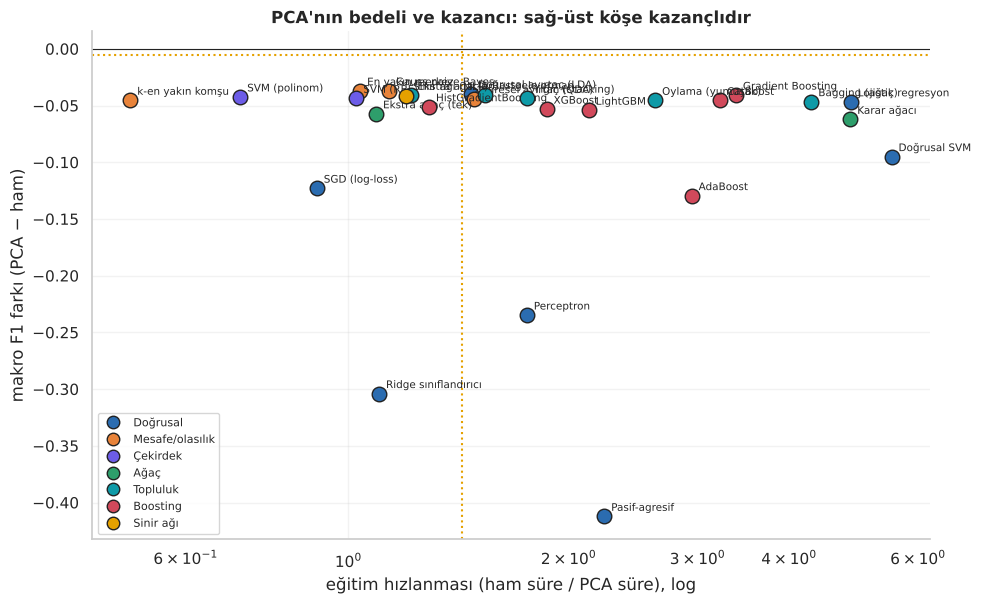

,Algoritma,Hızlanma_medyan,ΔF1_ort
Aile,,,
Ağaç,2,2.9686,-0.0598
Boosting,6,2.5363,-0.0624
Doğrusal,7,1.7529,-0.1793
Mesafe/olasılık,4,1.0866,-0.0408
Sinir ağı,1,1.1991,-0.0412
Topluluk,5,1.7537,-0.0434
Çekirdek,2,0.8686,-0.0430


📄 Rapor → outputs/reports/13_aile_ozeti.csv


In [20]:
fig, ax = plt.subplots(figsize=(10, 6.2))
for ad, r in sure.iterrows():
    ax.scatter(r["Hızlanma (eğitim)"], r["Δ F1 (PCA−Ham)"], s=110, color=aile_renk[r["Aile"]], edgecolor="#222", zorder=3)
    ax.annotate(ad, (r["Hızlanma (eğitim)"], r["Δ F1 (PCA−Ham)"]), xytext=(5, 4), textcoords="offset points", fontsize=7.5)
ax.axhline(-0.005, color=RENK["altin"], ls=":"); ax.axhline(0, color="#222", lw=.8); ax.axvline(1 / 0.7, color=RENK["altin"], ls=":")
ax.set_xscale("log"); ax.set_xlabel("eğitim hızlanması (ham süre / PCA süre), log"); ax.set_ylabel("makro F1 farkı (PCA − ham)")
ax.set_title("PCA'nın bedeli ve kazancı: sağ-üst köşe kazançlıdır")
handles = [plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=c, markeredgecolor="#222", markersize=9, label=a) for a, c in aile_renk.items() if a != "Taban"]
ax.legend(handles=handles, fontsize=8, loc="lower left"); fig.tight_layout(); kaydet(fig, "09_hiz_x_dogruluk"); plt.show()

aile_ozet = sure.groupby("Aile").agg(Algoritma=("Hızlanma (eğitim)", "size"), Hızlanma_medyan=("Hızlanma (eğitim)", "median"), ΔF1_ort=("Δ F1 (PCA−Ham)", "mean")).round(4)
display(aile_ozet); rapor_kaydet(aile_ozet, "13_aile_ozeti")

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

PCA bir **takas**tır: bileşen sayısı azalınca **özellik başına hesap** azalır (özellikle çok ağaç/yineleme yapan modellerde hız artar), ama **bilgi de azalır**. Aile tablosu hangi ailelerin PCA'dan **kazanç/kayıp** gördüğünü gösteriyor. Sonucu **kendi verinizde ölçmeden** genelleyemezsiniz.

</td></tr></table>

<a id="p9"></a>

<p align="center">
  <img src="assets/proje_09.svg" width="100%" alt="Bölüm 9">
</p>

### 🎚️ 9.1 · Bileşen Sayısı Arttıkça

Yarışta kural gereği önceden seçilen tek bir `k` kullandık. Peki başka `k` değerlerinde ne olur? Yedi farklı yapıdaki model için `k = 1…16` eğrisini çizelim; kesikli çizgi **PCA'sız (ham)** başarıdır. `k = 16`, bilgi kaybı olmadan **yalnızca döndürülmüş** uzaydır.

k,1,2,3,4,5,6,8,10,12,16
Algoritma,,,,,,,,,,
Gauss naive Bayes,0.6085,0.8505,0.8580,0.8701,0.9143,0.9155,0.9147,0.9118,0.9088,0.8978
LightGBM,0.6073,0.8432,0.8688,0.8868,0.9336,0.9367,0.9380,0.9379,0.9388,0.9382
Lojistik regresyon,0.6116,0.8656,0.8765,0.8905,0.9356,0.9360,0.9371,0.9372,0.9373,0.9371
Rastgele orman,0.5350,0.8501,0.8746,0.8935,0.9356,0.9389,0.9372,0.9378,0.9387,0.9397
SVM (RBF),0.5987,0.8644,0.8826,0.8982,0.9404,0.9408,0.9418,0.9418,0.9419,0.9418
Sinir ağı (MLP),0.6092,0.8657,0.8789,0.8954,0.9338,0.9395,0.9395,0.9382,0.9385,0.9390
k-en yakın komşu,0.5904,0.8583,0.8765,0.8892,0.9340,0.9338,0.9345,0.9346,0.9346,0.9346


📄 Rapor → outputs/reports/14_k_egrisi.csv
💾 Kaydedildi → outputs/figures/10_k_egrisi.png


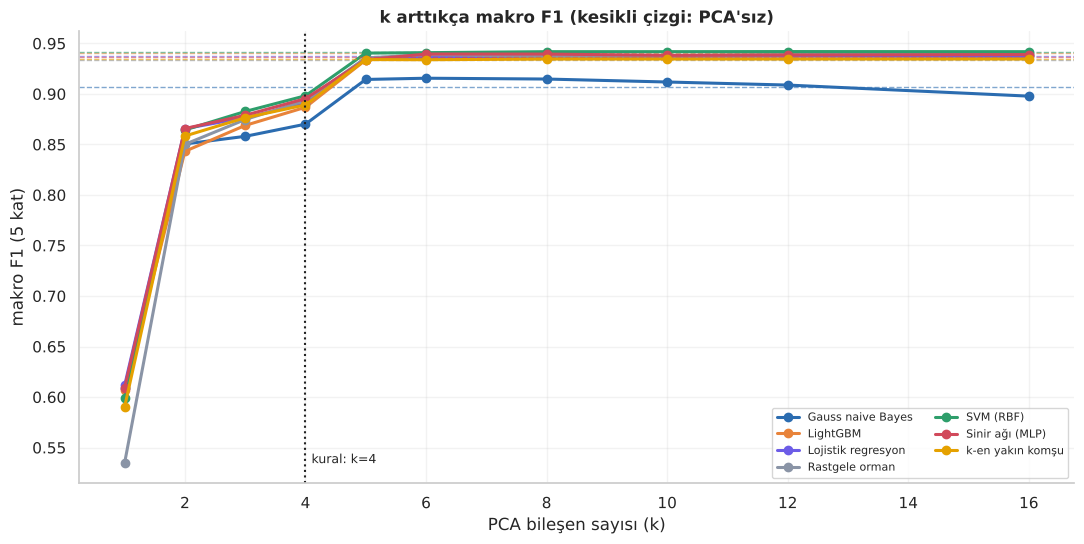

**Okuma:** ham başarıya **0,005 yakınlığa** ulaşmak için gereken en küçük k: **Gauss naive Bayes** → 5, **LightGBM** → 6, **Lojistik regresyon** → 5, **Rastgele orman** → 5, **SVM (RBF)** → 5, **Sinir ağı (MLP)** → 5, **k-en yakın komşu** → 5. Kuralın seçtiği k=4 bu modeller için yeterli mi? Tablodan okuyun.

In [21]:
temsil = {"Lojistik regresyon": LogisticRegression(max_iter=3000), "k-en yakın komşu": KNeighborsClassifier(7), "SVM (RBF)": SVC(),
          "Gauss naive Bayes": GaussianNB(), "Rastgele orman": RandomForestClassifier(100, n_jobs=1, random_state=RS),
          "LightGBM": LGBMClassifier(n_estimators=150, n_jobs=1, random_state=RS, verbosity=-1), "Sinir ağı (MLP)": MLPClassifier((64, 32), max_iter=300, early_stopping=True, random_state=RS)}
KS = [1, 2, 3, 4, 5, 6, 8, 10, 12, 16]
def k_kat(ad, k, tr, va):
    m = boru(temsil[ad], k); m.fit(Xtr.iloc[tr], ytr[tr]); return f1_score(ytr[va], m.predict(Xtr.iloc[va]), average="macro")
isler = [(ad, k, i) for ad in temsil for k in KS + [None] for i in range(5)]
sk = Parallel(n_jobs=N_JOBS)(delayed(k_kat)(ad, k, katlar[i][0], katlar[i][1]) for ad, k, i in isler)
keg = pd.DataFrame([{"Algoritma": ad, "k": (k if k else 0), "F1": s} for (ad, k, i), s in zip(isler, sk)]).groupby(["Algoritma", "k"])["F1"].mean().unstack("k")
ham_cizgi = keg[0]; keg = keg.drop(columns=0)
display(keg.round(4)); rapor_kaydet(keg, "14_k_egrisi")

fig, ax = plt.subplots(figsize=(11, 5.6))
renkler = [RENK["mavi"], RENK["turuncu"], RENK["mor"], RENK["gri"], RENK["yesil"], RENK["pembe"], RENK["altin"]]
for (ad, r), c in zip(keg.iterrows(), renkler):
    ax.plot(KS, r.values, "o-", color=c, lw=2.2, label=ad); ax.axhline(ham_cizgi[ad], color=c, ls="--", lw=1, alpha=.6)
ax.axvline(K_95, color="#222", ls=":"); ax.text(K_95 + .1, ax.get_ylim()[0] + .02, f"kural: k={K_95}", fontsize=9)
ax.set_xlabel("PCA bileşen sayısı (k)"); ax.set_ylabel("makro F1 (5 kat)"); ax.set_title("k arttıkça makro F1 (kesikli çizgi: PCA'sız)"); ax.legend(ncol=2, fontsize=8, loc="lower right")
fig.tight_layout(); kaydet(fig, "10_k_egrisi"); plt.show()
plato = {ad: next((k for k in KS if r[k] >= ham_cizgi[ad] - 0.005), None) for ad, r in keg.iterrows()}
display(Markdown("**Okuma:** ham başarıya **0,005 yakınlığa** ulaşmak için gereken en küçük k: " + ", ".join(f"**{a}** → {v}" for a, v in plato.items()) + f". Kuralın seçtiği k={K_95} bu modeller için yeterli mi? Tablodan okuyun."))

### 🎞️ 9.2 · Bileşen Ekledikçe Türler Ayrışıyor (Animasyon)

SVM (RBF) modelini `k = 1…8` bileşenle eğitip **iç doğrulama** verisinin karışıklık matrisini izliyoruz. Köşegen (doğru tahmin) koyulaştıkça ayrışma artıyor.

🎞️ Animasyon → outputs/figures/11_bilesen_ekledikce.gif


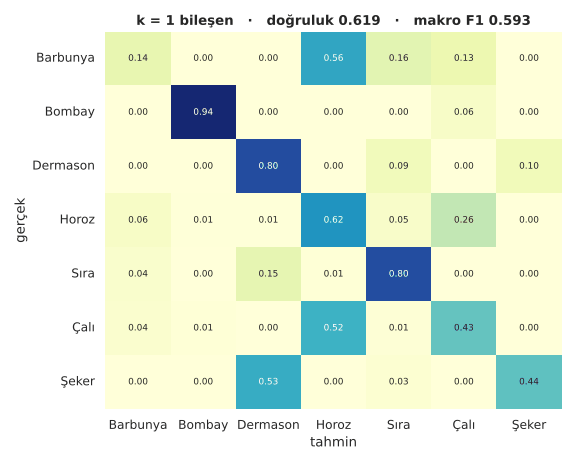

In [22]:
a_, b_, c_, e_ = train_test_split(Xtr, ytr, test_size=0.25, stratify=ytr, random_state=RS)
def kare(i, fig):
    k = i + 1
    m = boru(SVC(), k).fit(a_, c_); tah = m.predict(b_)
    cm = confusion_matrix(e_, tah, normalize="true", labels=range(7)); ax = fig.add_subplot(1, 1, 1)
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1, cbar=False, ax=ax, annot_kws={"size": 8},
                xticklabels=le.classes_, yticklabels=le.classes_)
    ax.set_title(f"k = {k} bileşen   ·   doğruluk {accuracy_score(e_, tah):.3f}   ·   makro F1 {f1_score(e_, tah, average='macro'):.3f}")
    ax.set_xlabel("tahmin"); ax.set_ylabel("gerçek"); ax.grid(False); fig.tight_layout()
gif_kaydet(kare, 8, "11_bilesen_ekledikce", figsize=(7.2, 5.8), fps=1.4)

<a id="p10"></a>

<p align="center">
  <img src="assets/proje_10.svg" width="100%" alt="Bölüm 10">
</p>

### 🛠️ 10.1 · PCA da Bir Düğme: Birlikte Ayarlayalım

Üç model ailesi seçtik: **SVM (RBF)** (çekirdek), **LightGBM** (boosting), **Sinir ağı (MLP)**. Her biri için **iki ayrı rastgele arama** kuruyoruz:

- **PCA'sız:** yalnızca modelin kendi düğmeleri
- **PCA'lı:** modelin düğmeleri **+ `k`** (PCA'nın bileşen sayısı, 4–16)

Arama **5 katlı çapraz doğrulama** ile yalnızca eğitim verisinde, makro F1 üzerinden yapılır. Sonra seçimin **iyimserliğini** kırmak için en iyi ayarları **taze katlarda** (5×2) yeniden değerlendireceğiz.

In [23]:
PCA_K = [4, 5, 6, 7, 8, 10, 12, 16]
def arama_kur(ad, pca_kullan):
    if ad == "SVM (RBF)":
        model, dag = SVC(), {"model__C": loguniform(1, 300), "model__gamma": loguniform(1e-3, 0.5)}; n_iter = 25
    elif ad == "LightGBM":
        model = LGBMClassifier(n_jobs=1, random_state=RS, verbosity=-1)
        dag = {"model__n_estimators": randint(100, 500), "model__learning_rate": loguniform(0.02, 0.2), "model__num_leaves": randint(8, 48),
               "model__min_child_samples": randint(5, 60), "model__subsample": uniform(0.6, 0.4), "model__subsample_freq": [1],
               "model__colsample_bytree": uniform(0.5, 0.5), "model__reg_lambda": loguniform(1e-2, 20)}; n_iter = 20
    else:
        model = MLPClassifier(max_iter=400, early_stopping=True, random_state=RS)
        dag = {"model__hidden_layer_sizes": [(32,), (64,), (64, 32), (128, 64), (128, 64, 32)], "model__alpha": loguniform(1e-5, 1e-1),
               "model__learning_rate_init": loguniform(5e-4, 1e-2)}; n_iter = 25
    pipe = Pipeline([("olcek", StandardScaler()), ("pca", PCA(random_state=RS)), ("model", model)])
    dag = dict(dag)
    dag["pca"] = [PCA(n_components=k, random_state=RS) for k in PCA_K] if pca_kullan else ["passthrough"]
    return RandomizedSearchCV(pipe, dag, n_iter=n_iter, scoring="f1_macro", cv=CV_ANA, n_jobs=N_JOBS, random_state=RS, refit=True)

aramalar = {}; t0 = time.perf_counter()
for ad in ["SVM (RBF)", "LightGBM", "Sinir ağı (MLP)"]:
    for pk in [False, True]:
        t1 = time.perf_counter(); s = arama_kur(ad, pk).fit(Xtr, ytr)
        aramalar[(ad, "PCA'lı" if pk else "PCA'sız")] = s
        print(f"✅ {ad:16s} {'PCA' if pk else 'ham'} → CV makro F1 {s.best_score_:.4f}  ({time.perf_counter()-t1:.0f} sn)")
print(f"⏱️ Toplam arama süresi: {time.perf_counter()-t0:.0f} sn")

✅ SVM (RBF)        ham → CV makro F1 0.9440  (17 sn)


✅ SVM (RBF)        PCA → CV makro F1 0.9420  (18 sn)


✅ LightGBM         ham → CV makro F1 0.9410  (66 sn)


✅ LightGBM         PCA → CV makro F1 0.9394  (58 sn)


✅ Sinir ağı (MLP)  ham → CV makro F1 0.9417  (38 sn)


✅ Sinir ağı (MLP)  PCA → CV makro F1 0.9423  (30 sn)
⏱️ Toplam arama süresi: 225 sn


### 🔍 10.2 · Taze Katlarda Doğrulama ve Final Seçimi

Aramada seçilen ayarın skoru **iyimserdir** (en iyiyi seçtik). Adil karşılaştırma için her adayı, aramanın görmediği **taze katlarda** (5×2) değerlendirip **önceden yazılmış kural 3**'ü uyguluyoruz: makro F1 en yüksek olan; fark ≤ 0,002 ise daha hızlı olan.

,F1_taze,F1_std,Dogruluk,Egitim_sn,CV (arama) F1,Seçilen PCA adımı,Varsayılan F1 (yarış)
Aday,,,,,,,
SVM (RBF) · PCA'lı,0.9424,0.0052,0.9312,0.4390,0.9420,k=8,0.8982
SVM (RBF) · PCA'sız,0.9422,0.0055,0.9305,0.3439,0.9440,yok,0.9418
Sinir ağı (MLP) · PCA'sız,0.9415,0.0050,0.9305,1.7853,0.9417,yok,0.9366
Sinir ağı (MLP) · PCA'lı,0.9410,0.0037,0.9296,1.1939,0.9423,k=10,0.8954
LightGBM · PCA'lı,0.9401,0.0043,0.9284,2.5379,0.9394,k=16,0.8863
LightGBM · PCA'sız,0.9384,0.0038,0.9260,1.1498,0.9410,yok,0.9404


📄 Rapor → outputs/reports/15_ayarli_adaylar.csv


🏆 **Final aday (kural 3):** **SVM (RBF) · PCA'sız**  ·  taze-kat makro F1 **0.9422** (en iyi 0.9424; havuzdaki aday sayısı 4)

{'model__C': np.float64(13.481575603601412), 'model__gamma': np.float64(0.13157287601765633)}
PCA adımı: passthrough
💾 Kaydedildi → outputs/figures/12_ayarli_adaylar.png


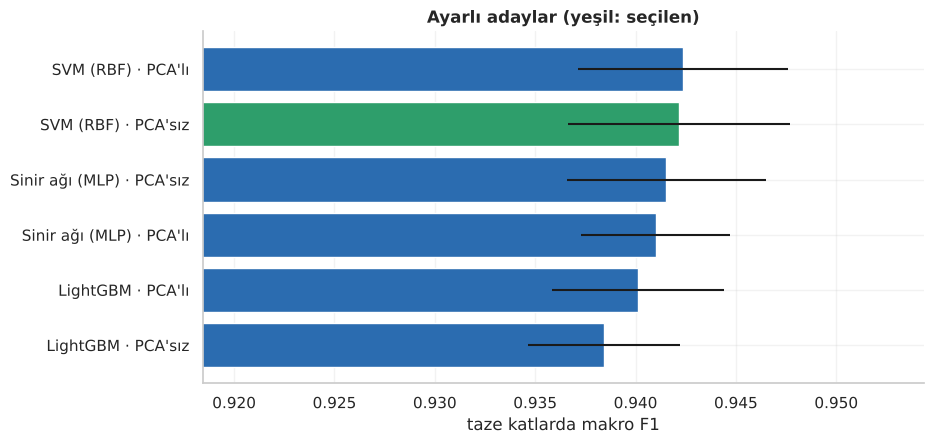

In [24]:
def taze_kat(anahtar, i):
    tr, va = katlar_taze[i]; m = clone(aramalar[anahtar].best_estimator_)
    t0 = time.perf_counter(); m.fit(Xtr.iloc[tr], ytr[tr]); egitim = time.perf_counter() - t0
    tah = m.predict(Xtr.iloc[va])
    return {"Aday": f"{anahtar[0]} · {anahtar[1]}", "Makro F1": f1_score(ytr[va], tah, average="macro"), "Doğruluk": accuracy_score(ytr[va], tah), "Eğitim sn": egitim}
cikti = Parallel(n_jobs=N_JOBS)(delayed(taze_kat)(a, i) for a in aramalar for i in range(len(katlar_taze)))
tz2 = pd.DataFrame(cikti)
adaylar = tz2.groupby("Aday").agg(F1_taze=("Makro F1", "mean"), F1_std=("Makro F1", "std"), Dogruluk=("Doğruluk", "mean"), Egitim_sn=("Eğitim sn", "mean"))
ad2anahtar = {f"{a_[0]} · {a_[1]}": a_ for a_ in aramalar}          # tablo adı → (model, PCA'lı/PCA'sız)
adaylar["CV (arama) F1"] = [aramalar[ad2anahtar[i]].best_score_ for i in adaylar.index]
adaylar["Seçilen PCA adımı"] = [("k=%d" % aramalar[ad2anahtar[i]].best_estimator_.named_steps["pca"].n_components
                                 if aramalar[ad2anahtar[i]].best_estimator_.named_steps["pca"] != "passthrough" else "yok") for i in adaylar.index]
adaylar["Varsayılan F1 (yarış)"] = [yaris.loc[ad2anahtar[i][0], "Ham F1"] if ad2anahtar[i][1] == "PCA'sız" else yaris.loc[ad2anahtar[i][0], "PCA F1"] for i in adaylar.index]
adaylar = adaylar.sort_values("F1_taze", ascending=False); display(adaylar.round(4))
rapor_kaydet(adaylar, "15_ayarli_adaylar")

# Kural 3: en yüksek taze F1; en iyiden ≤ 0,002 geride kalanlar arasında en hızlısı
en_f1 = adaylar["F1_taze"].max(); havuz = adaylar[adaylar["F1_taze"] >= en_f1 - 0.002]
FINAL_AD = havuz["Egitim_sn"].idxmin(); fa, fk = FINAL_AD.split(" · ")
FINAL_ANAHTAR = (fa, fk); FINAL = clone(aramalar[FINAL_ANAHTAR].best_estimator_)
display(Markdown(f"🏆 **Final aday (kural 3):** **{FINAL_AD}**  ·  taze-kat makro F1 **{adaylar.loc[FINAL_AD,'F1_taze']:.4f}** (en iyi {en_f1:.4f}; havuzdaki aday sayısı {len(havuz)})"))
print({k: v for k, v in aramalar[FINAL_ANAHTAR].best_params_.items() if k != "pca"}); print("PCA adımı:", aramalar[FINAL_ANAHTAR].best_params_["pca"])

fig, ax = plt.subplots(figsize=(9.5, 4.6)); a2 = adaylar.iloc[::-1]
ax.barh(a2.index, a2["F1_taze"], xerr=a2["F1_std"], color=[RENK["yesil"] if i == FINAL_AD else RENK["mavi"] for i in a2.index])
ax.set_xlim(a2["F1_taze"].min() - .02, a2["F1_taze"].max() + .012); ax.set_xlabel("taze katlarda makro F1"); ax.set_title("Ayarlı adaylar (yeşil: seçilen)")
fig.tight_layout(); kaydet(fig, "12_ayarli_adaylar"); plt.show()

<a id="p11"></a>

<p align="center">
  <img src="assets/proje_11.svg" width="100%" alt="Bölüm 11">
</p>

### 🧭 11.1 · Permütasyon Önemi: Hangi Ölçü Karıştırılınca Başarı Düşüyor?

Final boru hattı ham ölçüleri alıp içeride PCA uyguluyorsa bile, **ham ölçü sütunlarını tek tek karıştırarak** (permütasyon) o ölçünün modele ne kadar yaradığını ölçebiliriz. Eğitim verisinin %25'i iç doğrulama olarak ayrılır.

Ölçü,Yuvarlaklık,Şekil 4,Kısa eksen,Alan,Dışbükey alan,Eş çap,Çevre,Şekil 1,Uzun eksen,Doluluk,En-boy oranı,Basıklık (eksantriklik),Şekil 3,Sıkılık,Kaplama oranı,Şekil 2
Önem,0.1149,0.1049,0.0888,0.0874,0.0869,0.0753,0.0653,0.0630,0.0429,0.0345,0.0206,0.0189,0.0148,0.0140,0.0091,0.0073
Std,0.0058,0.0048,0.0076,0.0053,0.0060,0.0056,0.0074,0.0054,0.0056,0.0036,0.0028,0.0025,0.0026,0.0033,0.0020,0.0030


💾 Kaydedildi → outputs/figures/13_permutasyon_onemi.png


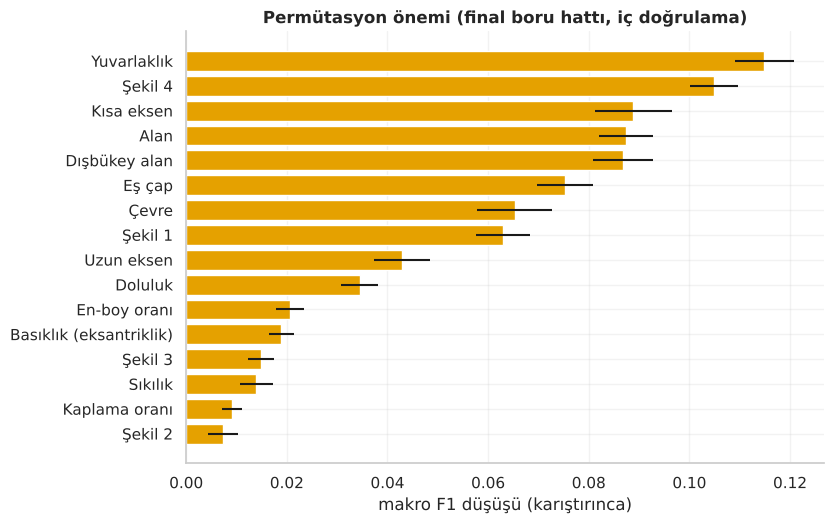

📄 Rapor → outputs/reports/16_permutasyon_onemi.csv


In [25]:
a_, b_, c_, e_ = train_test_split(Xtr, ytr, test_size=0.25, stratify=ytr, random_state=RS)
fm = clone(FINAL).fit(a_, c_)
pi = permutation_importance(fm, b_, e_, scoring="f1_macro", n_repeats=15, random_state=RS, n_jobs=N_JOBS)
imp = pd.DataFrame({"Ölçü": [TR_AD[o] for o in OZELLIKLER], "Önem": pi.importances_mean, "Std": pi.importances_std}).sort_values("Önem", ascending=False)
display(imp.set_index("Ölçü").round(4).T)
fig, ax = plt.subplots(figsize=(8.5, 5.4)); i2 = imp.iloc[::-1]
ax.barh(i2["Ölçü"], i2["Önem"], xerr=i2["Std"], color=RENK["altin"]); ax.set_xlabel("makro F1 düşüşü (karıştırınca)")
ax.set_title("Permütasyon önemi (final boru hattı, iç doğrulama)"); fig.tight_layout(); kaydet(fig, "13_permutasyon_onemi"); plt.show()
rapor_kaydet(imp.set_index("Ölçü"), "16_permutasyon_onemi")

### 🧪 11.2 · Ablasyon: Bilgi Grubunu Gerçekten Çıkarınca Ne Oluyor?

Önem grafiği **neden** değil **ilişki** gösterir. Ölçüleri üç mantıksal gruba ayırıp (**boyut**, **şekil oranları**, **şekil faktörleri**) her grubu tek tek **çıkarıp** ve **yalnız bırakıp** aynı boru hattını taze katlarda yeniden koşuyoruz.

,mean,std,Tüm ölçülere göre fark
Senaryo,,,
Tüm ölçüler (16),0.9422,0.0055,0.0000
− Boyut çıkarıldı,0.9417,0.0052,-0.0004
Yalnız Boyut,0.9255,0.0034,-0.0166
− Şekil oranları çıkarıldı,0.9352,0.0043,-0.0069
Yalnız Şekil oranları,0.7391,0.0098,-0.2030
− Şekil faktörleri çıkarıldı,0.9347,0.0038,-0.0074
Yalnız Şekil faktörleri,0.9087,0.0049,-0.0335


📄 Rapor → outputs/reports/17_ablasyon.csv
💾 Kaydedildi → outputs/figures/14_ablasyon.png


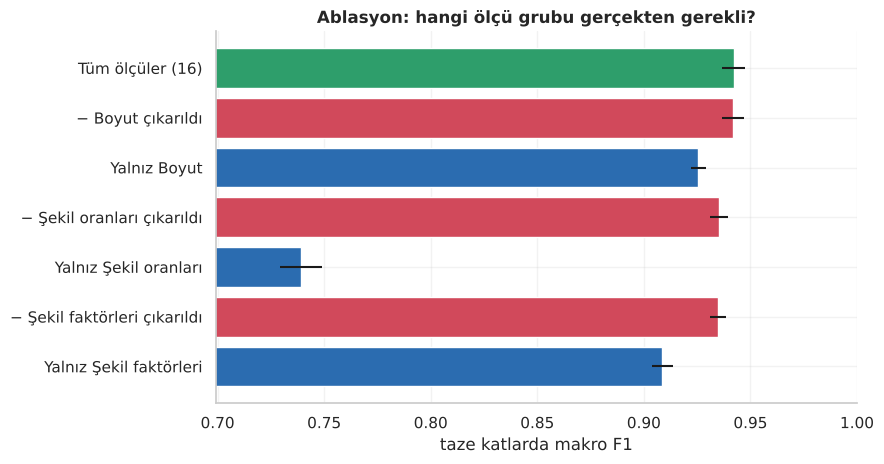

In [26]:
gruplar = {"Boyut": ["Area", "Perimeter", "MajorAxisLength", "MinorAxisLength", "ConvexArea", "EquivDiameter"],
           "Şekil oranları": ["AspectRation", "Eccentricity", "Extent", "Solidity", "roundness", "Compactness"],
           "Şekil faktörleri": ["ShapeFactor1", "ShapeFactor2", "ShapeFactor3", "ShapeFactor4"]}
def abl_kat(ad, kolonlar, i):
    tr, va = katlar_taze[i]; m = clone(FINAL)
    if "pca" in m.named_steps and m.named_steps["pca"] != "passthrough":
        k = m.named_steps["pca"].n_components
        if k > len(kolonlar): m.set_params(pca=PCA(n_components=len(kolonlar), random_state=RS))   # k, sütun sayısını aşamaz
    m.fit(Xtr.iloc[tr][kolonlar], ytr[tr]); return {"Senaryo": ad, "Makro F1": f1_score(ytr[va], m.predict(Xtr.iloc[va][kolonlar]), average="macro")}
senaryolar = {"Tüm ölçüler (16)": OZELLIKLER}
for g_, kol in gruplar.items():
    senaryolar[f"− {g_} çıkarıldı"] = [o for o in OZELLIKLER if o not in kol]
    senaryolar[f"Yalnız {g_}"] = kol
cikti = Parallel(n_jobs=N_JOBS)(delayed(abl_kat)(ad, kol, i) for ad, kol in senaryolar.items() for i in range(len(katlar_taze)))
abl = pd.DataFrame(cikti).groupby("Senaryo")["Makro F1"].agg(["mean", "std"]).loc[list(senaryolar)]
abl["Tüm ölçülere göre fark"] = abl["mean"] - abl.loc["Tüm ölçüler (16)", "mean"]
display(abl.round(4)); rapor_kaydet(abl, "17_ablasyon")
fig, ax = plt.subplots(figsize=(9, 4.8)); a3 = abl.iloc[::-1]
ax.barh(a3.index, a3["mean"], xerr=a3["std"], color=[RENK["yesil"] if "Tüm" in i else (RENK["pembe"] if "−" in i else RENK["mavi"]) for i in a3.index])
ax.set_xlim(a3["mean"].min() - .04, 1); ax.set_xlabel("taze katlarda makro F1"); ax.set_title("Ablasyon: hangi ölçü grubu gerçekten gerekli?")
fig.tight_layout(); kaydet(fig, "14_ablasyon"); plt.show()

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Dört ölçü bir arada okunmalı: **permütasyon önemi** hangi sütunun karıştırılınca zarar verdiğini, **ablasyon** ise bir bilgi grubunu çıkarınca gerçekte ne olduğunu gösterir. Birbirinin kopyası olan ölçülerde (alan–çevre–eksenler) **tek bir sütunu çıkarmak zarar vermez**; çünkü bilgi diğerlerinde de var. İşte PCA'nın bu **yedekliliği** tek bir bileşende toplamasının nedeni budur.

</td></tr></table>

<a id="p12"></a>

<p align="center">
  <img src="assets/proje_12.svg" width="100%" alt="Bölüm 12">
</p>

### 🏆 12.1 · Test Seti Açılıyor (Tek Sefer)

Final boru hattını **tüm eğitim verisinde** eğitip kilitli test setinde **bir kez** değerlendiriyoruz. Ayrıca bilgi için ham ve PCA'lı dünyadaki varsayılan lideri de test'e koyacağız; **ama seçim zaten yapıldı**.

In [27]:
# Final olasılık üretmeli (log-loss, ROC, kalibrasyon için): SVM ise probability=True ile yeniden kur
FINAL_TEST = clone(FINAL)
if "model" in FINAL_TEST.named_steps and isinstance(FINAL_TEST.named_steps["model"], SVC):
    FINAL_TEST.set_params(model__probability=True, model__random_state=RS)
FINAL_TEST.fit(Xtr, ytr)
p_te = FINAL_TEST.predict_proba(Xte); tah_te = p_te.argmax(1)
tdict = {"Doğruluk": accuracy_score(yte, tah_te), "Makro F1": f1_score(yte, tah_te, average="macro"), "Dengeli doğruluk": balanced_accuracy_score(yte, tah_te),
         "Log-loss": log_loss(yte, p_te, labels=range(7)), "ROC AUC (OvR makro)": roc_auc_score(yte, p_te, multi_class="ovr", average="macro")}
dm = DummyClassifier(strategy="most_frequent").fit(Xtr, ytr); taban_f1 = f1_score(yte, dm.predict(Xte), average="macro")
final_tab = pd.DataFrame({"Final model": tdict}); final_tab.loc["Taban makro F1"] = taban_f1
display(final_tab.round(4)); rapor_kaydet(final_tab, "18_final_test")

# Bilgi amaçlı: yarışın en iyi birkaç algoritması ham ve PCA'lı olarak test'te
tk = []
for ad in [a for a in yaris.index if not a.startswith("Taban")][:8]:
    for gor, k in [("Ham", None), ("PCA", K_95)]:
        m = boru(YARISCI[ad][1], k).fit(Xtr, ytr); tahm = m.predict(Xte)
        tk.append({"Algoritma": ad, "Görünüm": gor, "Test makro F1": f1_score(yte, tahm, average="macro"), "Test doğruluk": accuracy_score(yte, tahm)})
tk = pd.DataFrame(tk).pivot(index="Algoritma", columns="Görünüm", values=["Test makro F1", "Test doğruluk"]).round(4)
display(tk); rapor_kaydet(tk, "19_test_karnesi_bilgi")

,Final model
Doğruluk,0.9280
Makro F1,0.9389
Dengeli doğruluk,0.9360
Log-loss,0.2172
ROC AUC (OvR makro),0.9940
Taban makro F1,0.0593


📄 Rapor → outputs/reports/18_final_test.csv


Test makro F1         Test doğruluk        
Görünüm                        Ham     PCA           Ham     PCA
Algoritma                                                       
CatBoost                    0.9349  0.8862        0.9217  0.8834
HistGradientBoosting        0.9335  0.8863        0.9206  0.8834
LightGBM                    0.9336  0.8807        0.9203  0.8778
Lojistik regresyon          0.9289  0.8876        0.9166  0.8841
Oylama (yumuşak)            0.9380  0.8869        0.9265  0.8837
SVM (RBF)                   0.9376  0.8905        0.9265  0.8889
XGBoost                     0.9314  0.8729        0.9184  0.8704
Yığın (stacking)            0.9333  0.8895        0.9217  0.8856

📄 Rapor → outputs/reports/19_test_karnesi_bilgi.csv


### 🧮 12.2 · Karışıklık Matrisi, ROC ve Tür Karnesi

,precision,recall,f1-score,support
Barbunya,0.964,0.906,0.934,265.000
Bombay,1.000,1.000,1.000,104.000
Dermason,0.906,0.948,0.926,709.000
Horoz,0.942,0.960,0.951,372.000
Sıra,0.888,0.858,0.873,527.000
Çalı,0.941,0.936,0.938,326.000
Şeker,0.955,0.946,0.950,406.000
accuracy,0.928,0.928,0.928,0.928
macro avg,0.942,0.936,0.939,2709.000
weighted avg,0.928,0.928,0.928,2709.000


📄 Rapor → outputs/reports/20_tur_karnesi.csv


💾 Kaydedildi → outputs/figures/15_final_test.png


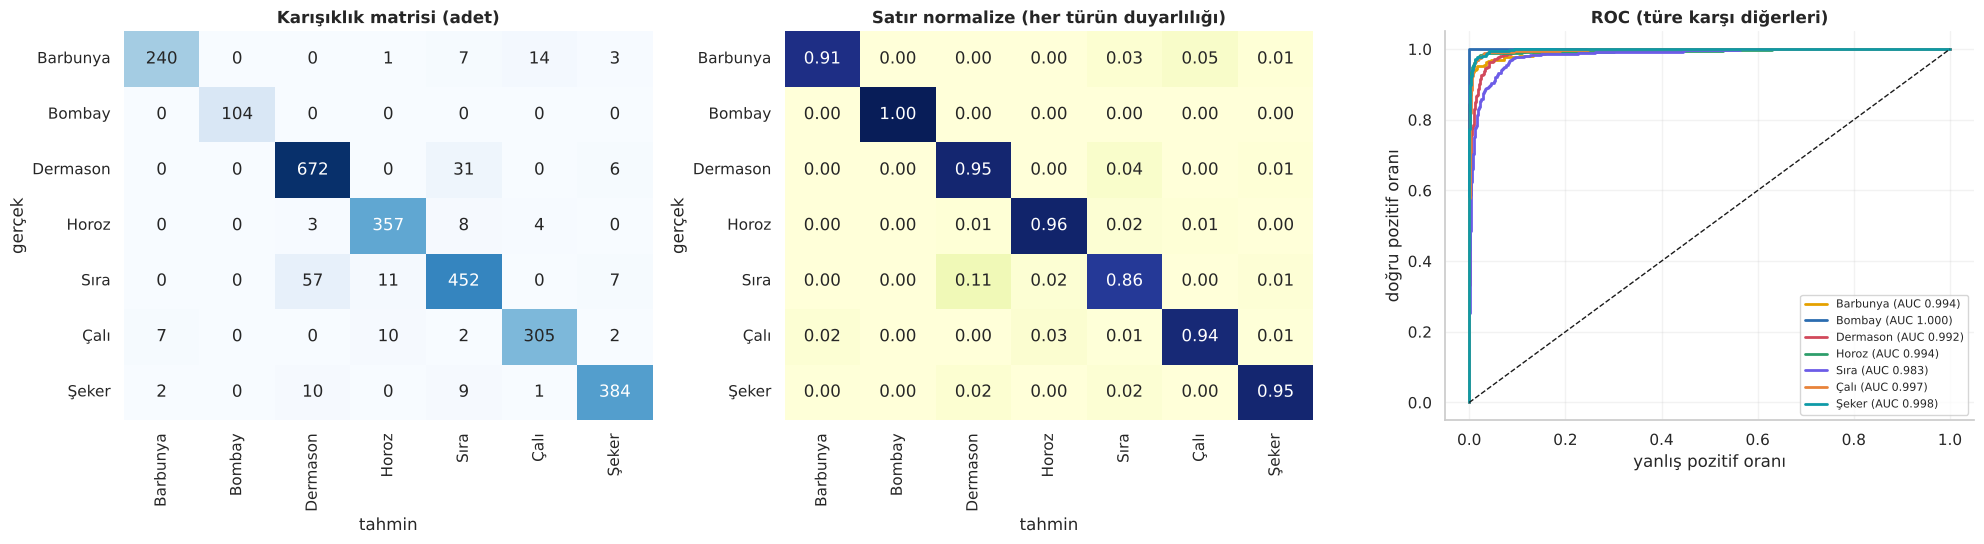

,,Adet
Gerçek,Tahmin,
Sıra,Dermason,57
Dermason,Sıra,31
Barbunya,Çalı,14
Sıra,Horoz,11
Şeker,Dermason,10
Çalı,Horoz,10


In [28]:
rapor = pd.DataFrame(classification_report(yte, tah_te, target_names=le.classes_, output_dict=True)).T.round(3)
display(rapor); rapor_kaydet(rapor, "20_tur_karnesi")

cm = confusion_matrix(yte, tah_te); cmn = confusion_matrix(yte, tah_te, normalize="true")
Yb = label_binarize(yte, classes=range(7))
from sklearn.metrics import roc_curve
fig, ax = plt.subplots(1, 3, figsize=(20, 5.6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_, ax=ax[0], cbar=False); ax[0].set_title("Karışıklık matrisi (adet)"); ax[0].grid(False)
sns.heatmap(cmn, annot=True, fmt=".2f", cmap="YlGnBu", xticklabels=le.classes_, yticklabels=le.classes_, ax=ax[1], cbar=False, vmin=0, vmax=1); ax[1].set_title("Satır normalize (her türün duyarlılığı)"); ax[1].grid(False)
for j, t in enumerate(le.classes_):
    fpr, tpr, _ = roc_curve(Yb[:, j], p_te[:, j]); ax[2].plot(fpr, tpr, lw=2, color=SINIF_RENK[t], label=f"{t} (AUC {roc_auc_score(Yb[:, j], p_te[:, j]):.3f})")
ax[2].plot([0, 1], [0, 1], "k--", lw=1); ax[2].set_xlabel("yanlış pozitif oranı"); ax[2].set_ylabel("doğru pozitif oranı"); ax[2].set_title("ROC (türe karşı diğerleri)"); ax[2].legend(fontsize=8)
for a in ax[:2]: a.set_xlabel("tahmin"); a.set_ylabel("gerçek")
fig.tight_layout(); kaydet(fig, "15_final_test"); plt.show()

# En çok karıştırılan çiftler
cf = [(le.classes_[i], le.classes_[j], cm[i, j]) for i in range(7) for j in range(7) if i != j and cm[i, j] > 0]
cf = pd.DataFrame(cf, columns=["Gerçek", "Tahmin", "Adet"]).sort_values("Adet", ascending=False).head(6); display(cf.set_index(["Gerçek", "Tahmin"]))

### 🚨 12.3 · En Kötü Hatalar: Model "Çok Emin" Olduğu Hâlde Yanılan Fasulyeler

In [29]:
hata = Xte.rename(columns=TR_AD)[["Alan", "Uzun eksen", "Kısa eksen", "Yuvarlaklık", "Sıkılık"]].copy()
hata["Gerçek"] = le.classes_[yte]; hata["Tahmin"] = le.classes_[tah_te]; hata["Güven"] = p_te.max(1)
kotu = hata[hata["Gerçek"] != hata["Tahmin"]].sort_values("Güven", ascending=False).head(8)
display(kotu.round(3)); rapor_kaydet(kotu, "21_en_kotu_hatalar", index=False)
print(f"Toplam hata: {(yte != tah_te).sum()} / {len(yte)}  ·  hata yapılan fasulyelerin medyan güveni: {hata[hata['Gerçek'] != hata['Tahmin']]['Güven'].median():.2f}")

,Alan,Uzun eksen,Kısa eksen,Yuvarlaklık,Sıkılık,Gerçek,Tahmin,Güven
843,51338,348.682,189.332,0.792,0.733,Sıra,Horoz,0.998
646,59780,390.400,196.325,0.786,0.707,Çalı,Horoz,0.997
470,48160,304.528,202.716,0.880,0.813,Barbunya,Sıra,0.992
269,68451,384.894,228.071,0.857,0.767,Barbunya,Çalı,0.991
2681,35827,269.608,169.492,0.909,0.792,Sıra,Dermason,0.986
2429,71940,399.303,230.493,0.846,0.758,Barbunya,Çalı,0.983
2344,54343,303.848,228.016,0.907,0.866,Çalı,Şeker,0.981
796,50954,330.155,198.462,0.854,0.771,Çalı,Sıra,0.978


📄 Rapor → outputs/reports/21_en_kotu_hatalar.csv
Toplam hata: 195 / 2709  ·  hata yapılan fasulyelerin medyan güveni: 0.74


<table><tr><td>

<img src="assets/etiket_not.svg" height="34" alt="Not">

Karışıklık matrisinde hataların **belirli çiftlerde** (örneğin Dermason–Sıra, Barbunya–Çalı) yoğunlaştığına bakın: modelin genel "zayıflığı" değil, **fiziksel olarak birbirine benzeyen türlerin** ölçü bulutlarının üst üste binmesidir. Daha iyi bir algoritma bu örtüşmeyi tamamen kapatamaz; yeni bir **ölçü** (renk, doku gibi) gerekir.

</td></tr></table>

<a id="p13"></a>

<p align="center">
  <img src="assets/proje_13.svg" width="100%" alt="Bölüm 13">
</p>

### ⚖️ 13.1 · Segment Denetimi: Boyut Dilimlerine Göre Başarı

Genel doğruluk, **belirli dilimlerde** zayıflığı gizleyebilir. Test setini **fasulye büyüklüğüne** (alan çeyrekleri) ve **gerçek türe** göre dilimleyip doğruluğu **Wilson %95 aralığıyla** raporluyoruz. (Küçük gruplarda sonuçlar belirsiz; aralık geniş çıkabilir.)

,Segment türü,Segment,n,Doğruluk,%95 alt,%95 üst
0,Boyut,Q1 küçük,678,0.960,0.943,0.972
1,Boyut,Q2,677,0.866,0.838,0.889
2,Boyut,Q3,677,0.925,0.902,0.942
3,Boyut,Q4 büyük,677,0.962,0.944,0.974
4,Tür,Barbunya,265,0.906,0.864,0.935
5,Tür,Bombay,104,1.000,0.964,1.000
6,Tür,Dermason,709,0.948,0.929,0.962
7,Tür,Horoz,372,0.960,0.935,0.975
8,Tür,Sıra,527,0.858,0.825,0.885
9,Tür,Çalı,326,0.936,0.904,0.957


📄 Rapor → outputs/reports/22_segment_denetimi.csv
💾 Kaydedildi → outputs/figures/16_segment_dogrulugu.png


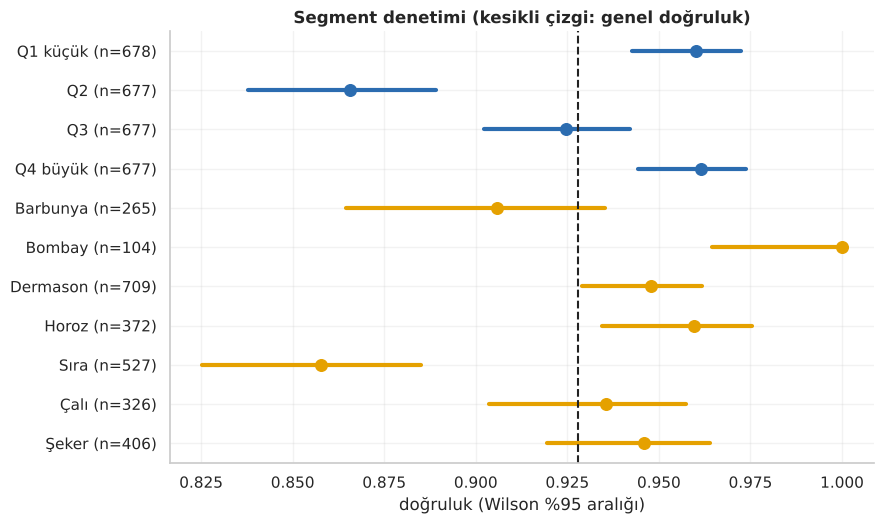

**Okuma:** en düşük doğruluklu segmentler: **Sıra** (0.858, n=527), **Q2** (0.866, n=677), **Barbunya** (0.906, n=265). Orta boy fasulyeler, farklı türlerin ölçü bulutlarının **kesiştiği bölgededir**; büyük ve küçük uçlarda ayrım kolaylaşır.

In [30]:
seg = pd.DataFrame({"Alan": Xte["Area"].values, "Gerçek": le.classes_[yte], "Doğru": (yte == tah_te).astype(int)})
seg["Boyut dilimi"] = pd.qcut(seg["Alan"], 4, labels=["Q1 küçük", "Q2", "Q3", "Q4 büyük"])
satir = []
for ad, g_ in [("Boyut", seg.groupby("Boyut dilimi", observed=True)), ("Tür", seg.groupby("Gerçek"))]:
    for k_, v in g_:
        n_ = len(v); k_dog = int(v["Doğru"].sum()); lo, hi = wilson(k_dog, n_)
        satir.append({"Segment türü": ad, "Segment": str(k_), "n": n_, "Doğruluk": k_dog / n_, "%95 alt": lo, "%95 üst": hi})
sd = pd.DataFrame(satir); display(sd.round(3)); rapor_kaydet(sd, "22_segment_denetimi", index=False)
fig, ax = plt.subplots(figsize=(9, 5.4)); s2 = sd.iloc[::-1].reset_index(drop=True)
for i, r in s2.iterrows():
    c = RENK["mavi"] if r["Segment türü"] == "Boyut" else RENK["altin"]
    ax.plot([r["%95 alt"], r["%95 üst"]], [i, i], color=c, lw=3); ax.scatter(r["Doğruluk"], i, s=70, color=c, zorder=3)
ax.set_yticks(range(len(s2))); ax.set_yticklabels([f"{r['Segment']} (n={r['n']})" for _, r in s2.iterrows()]); ax.axvline(tdict["Doğruluk"], color="#222", ls="--")
ax.set_xlabel("doğruluk (Wilson %95 aralığı)"); ax.set_title("Segment denetimi (kesikli çizgi: genel doğruluk)"); fig.tight_layout(); kaydet(fig, "16_segment_dogrulugu"); plt.show()
dusuk = sd.sort_values("Doğruluk").head(3)
display(Markdown("**Okuma:** en düşük doğruluklu segmentler: " + ", ".join(f"**{r['Segment']}** ({r['Doğruluk']:.3f}, n={r['n']})" for _, r in dusuk.iterrows()) + ". Orta boy fasulyeler, farklı türlerin ölçü bulutlarının **kesiştiği bölgededir**; büyük ve küçük uçlarda ayrım kolaylaşır."))

### 📐 13.2 · Kalibrasyon: "%90 Eminim" Gerçekten %90 mı?

Model olasılıklarına **güvenebilmek** için güven (en yüksek olasılık) ile gerçek doğruluğun örtüşmesi gerekir. **Beklenen kalibrasyon hatası (ECE)** bu farkın ortalamasıdır. Kalibrasyonu **eğitim verisinde** `CalibratedClassifierCV` ile düzeltmeyi deniyoruz.

,Ham olasılık,Sigmoid kalibre
ECE,0.0136,0.0337
Log-loss,0.2172,0.2788
Doğruluk,0.9280,0.9295


📄 Rapor → outputs/reports/23_kalibrasyon.csv
💾 Kaydedildi → outputs/figures/17_kalibrasyon.png


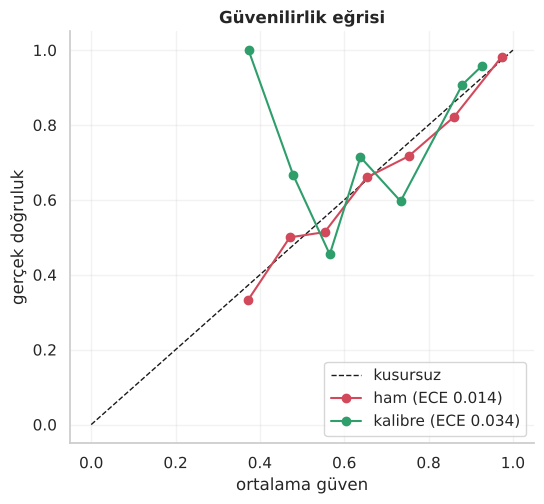

**Okuma:** ECE ham **0.0136**, sigmoid kalibre **0.0337**. Kalibrasyon bu modelde hatayı **artırdı**: model olasılıkları (SVM'nin Platt ölçeklemesi dâhil) zaten iyi kalibre; **her zaman kalibre etmek gerekmez, ölçüp karar verilir**.

In [31]:
def ece(p, y, n_kutu=10):
    guven = p.max(1); dogru = (p.argmax(1) == y); kutu = np.minimum((guven * n_kutu).astype(int), n_kutu - 1); toplam = 0.0; satirlar = []
    for b in range(n_kutu):
        m = kutu == b
        if m.sum(): toplam += m.mean() * abs(dogru[m].mean() - guven[m].mean()); satirlar.append((guven[m].mean(), dogru[m].mean(), m.sum()))
    return toplam, np.array(satirlar)

kal = CalibratedClassifierCV(clone(FINAL_TEST), method="sigmoid", cv=5).fit(Xtr, ytr)
p_kal = kal.predict_proba(Xte)
e0, r0 = ece(p_te, yte); e1, r1 = ece(p_kal, yte)
kt = pd.DataFrame({"Ham olasılık": [e0, log_loss(yte, p_te), accuracy_score(yte, p_te.argmax(1))],
                   "Sigmoid kalibre": [e1, log_loss(yte, p_kal), accuracy_score(yte, p_kal.argmax(1))]}, index=["ECE", "Log-loss", "Doğruluk"])
display(kt.round(4)); rapor_kaydet(kt, "23_kalibrasyon")
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="kusursuz"); ax.plot(r0[:, 0], r0[:, 1], "o-", color=RENK["pembe"], label=f"ham (ECE {e0:.3f})"); ax.plot(r1[:, 0], r1[:, 1], "o-", color=RENK["yesil"], label=f"kalibre (ECE {e1:.3f})")
ax.set_xlabel("ortalama güven"); ax.set_ylabel("gerçek doğruluk"); ax.set_title("Güvenilirlik eğrisi"); ax.legend(); fig.tight_layout(); kaydet(fig, "17_kalibrasyon"); plt.show()
display(Markdown(f"**Okuma:** ECE ham **{e0:.4f}**, sigmoid kalibre **{e1:.4f}**. " + ("Kalibrasyon hatayı **azalttı**." if e1 < e0 else "Kalibrasyon bu modelde hatayı **artırdı**: model olasılıkları (SVM'nin Platt ölçeklemesi dâhil) zaten iyi kalibre; **her zaman kalibre etmek gerekmez, ölçüp karar verilir**.")))

### 💶 13.3 · Maliyete Duyarlı Karar ve "Emin Değilsem İnsana Sor"

**Senaryo (varsayımsal, gerçek bir iş verisi değildir):** büyük taneli ve yüksek fiyatlı türler (**Bombay, Barbunya, Çalı**) kutuya **başka bir türün** karışması **3 birim**, diğer hatalar **1 birim** maliyetli. Olasılıkları bilen bir model, doğruluğu en yükseğe değil **beklenen maliyeti en düşüğe** karar verebilir:

$$\hat{y} = \arg\min_j \sum_i p_i \, C_{ij}$$

Ayrıca bir **güven eşiği** koyarak şüpheli fasulyeleri **insan kontrolüne** yönlendiriyoruz. Eşik **eğitim verisinin çapraz-doğrulama tahminlerinde** (OOF) seçilir, test'te yalnızca uygulanır.

,Doğruluk,Toplam maliyet,Fasulye başına maliyet
argmax kararı,0.9280,251.0,0.0927
maliyet-duyarlı karar,0.9199,251.0,0.0927


📄 Rapor → outputs/reports/24_maliyet_karari.csv


,Eşik,OOF kabul oranı,OOF kabul doğruluğu,Test kabul oranı,Test kabul doğruluğu,İnsana giden
0,0.805,0.8876,0.9705,0.8834,0.9674,316


📄 Rapor → outputs/reports/25_guven_esigi.csv


**Okuma:** argmax kararı toplam maliyet **251**, maliyet-duyarlı karar **251**; doğruluk 0.9280 → 0.9199. Bu testte maliyet-duyarlı karar maliyeti **düşürmedi** (olasılıklar zaten çok keskin; kararı değiştirecek belirsiz örnek az). Dürüst sonuç budur.

💾 Kaydedildi → outputs/figures/18_guven_esigi.png


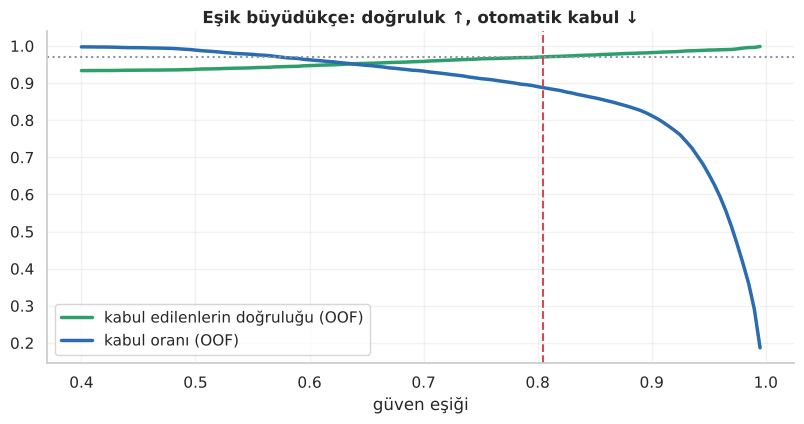

In [32]:
premium = [list(le.classes_).index(t) for t in ["Bombay", "Barbunya", "Çalı"]]
C = np.ones((7, 7)) - np.eye(7)                       # C[gerçek, tahmin]
for j in premium:
    C[:, j] *= 3.0; C[j, j] = 0.0                     # premium kutuya yanlış tür karışması 3 kat pahalı
C[np.arange(7), np.arange(7)] = 0.0
def toplam_maliyet(y, tah): return C[y, tah].sum()
maliyet_tah = lambda p: (p @ C).argmin(1)             # beklenen maliyeti en küçük sınıf
mt = pd.DataFrame({"Doğruluk": [accuracy_score(yte, tah_te), accuracy_score(yte, maliyet_tah(p_te))],
                   "Toplam maliyet": [toplam_maliyet(yte, tah_te), toplam_maliyet(yte, maliyet_tah(p_te))]}, index=["argmax kararı", "maliyet-duyarlı karar"])
mt["Fasulye başına maliyet"] = mt["Toplam maliyet"] / len(yte); display(mt.round(4)); rapor_kaydet(mt, "24_maliyet_karari")

# Güven eşiği: OOF üzerinde, kabul edilen fasulyelerde doğruluk ≥ 0,97 sağlayan en düşük eşik
p_oof = cross_val_predict(clone(FINAL_TEST), Xtr, ytr, cv=CV_ANA, method="predict_proba", n_jobs=N_JOBS)
guv_oof = p_oof.max(1); dog_oof = p_oof.argmax(1) == ytr
esik_dizi = np.linspace(0.4, 0.995, 120); hedef = 0.97
gecerli = [t for t in esik_dizi if dog_oof[guv_oof >= t].mean() >= hedef]
ESIK = min(gecerli) if gecerli else 0.99
guv_te = p_te.max(1); kabul = guv_te >= ESIK
red_tab = pd.DataFrame({"Eşik": [ESIK], "OOF kabul oranı": [(guv_oof >= ESIK).mean()], "OOF kabul doğruluğu": [dog_oof[guv_oof >= ESIK].mean()],
                        "Test kabul oranı": [kabul.mean()], "Test kabul doğruluğu": [(tah_te[kabul] == yte[kabul]).mean()], "İnsana giden": [int((~kabul).sum())]})
display(red_tab.round(4)); rapor_kaydet(red_tab, "25_guven_esigi", index=False)

display(Markdown(f"**Okuma:** argmax kararı toplam maliyet **{mt.iloc[0,1]:.0f}**, maliyet-duyarlı karar **{mt.iloc[1,1]:.0f}**; doğruluk {mt.iloc[0,0]:.4f} → {mt.iloc[1,0]:.4f}. "
                 + ("Maliyet-duyarlı karar **maliyeti düşürdü**." if mt.iloc[1,1] < mt.iloc[0,1] else "Bu testte maliyet-duyarlı karar maliyeti **düşürmedi** (olasılıklar zaten çok keskin; kararı değiştirecek belirsiz örnek az). Dürüst sonuç budur.")))
fig, ax = plt.subplots(figsize=(8.2, 4.4))
kap = [(dog_oof[guv_oof >= t].mean(), (guv_oof >= t).mean()) for t in esik_dizi]
ax.plot(esik_dizi, [k[0] for k in kap], color=RENK["yesil"], lw=2.5, label="kabul edilenlerin doğruluğu (OOF)"); ax.plot(esik_dizi, [k[1] for k in kap], color=RENK["mavi"], lw=2.5, label="kabul oranı (OOF)")
ax.axvline(ESIK, color=RENK["pembe"], ls="--"); ax.axhline(hedef, color=RENK["gri"], ls=":"); ax.set_xlabel("güven eşiği"); ax.set_title("Eşik büyüdükçe: doğruluk ↑, otomatik kabul ↓"); ax.legend()
fig.tight_layout(); kaydet(fig, "18_guven_esigi"); plt.show()

<table><tr><td>

<img src="assets/etiket_etik.svg" height="34" alt="Etik not">

Maliyet matrisi **varsayımsaldır**; gerçek bir işletmede fiyat farkı, müşteri şikâyeti ve geri çağırma maliyeti **iş birimiyle birlikte** ölçülüp yazılmalıdır. Güven eşiği ve "insana sor" mekanizması, hata maliyeti yüksek her kararda önerilir: modelin **ne zaman susması gerektiğini** de bilmesi gerekir.

</td></tr></table>

<a id="p14"></a>

<p align="center">
  <img src="assets/proje_14.svg" width="100%" alt="Bölüm 14">
</p>

### 🚨 14.1 · PCA ile Anomali: Tanımadığı Fasulyeyi Yakala

PCA'nın bir yan işi: **yeniden kurma hatası.** Bildiğimiz fasulyelerle (6 tür) PCA'yı eğitirsek, **bilmediği** bir türün fasulyesi bu bileşenlerle iyi **kurulamaz** (hata büyük çıkar). Bunu **her türü sırayla "yeni tür" sayarak** deneyelim (**leave-one-class-out**):

1. Eğitim verisinde bir türü ayır ("yabancı").
2. Kalan 6 türün %70'ine ölçekleyici + PCA(k) uydur; kalan %30'u "tanıdık" doğrulama olsun.
3. **Hata skoru:** yeniden kurma hatası (SPE) ve Hotelling T² (bileşenlerdeki uzaklık). Yabancı ↔ tanıdık ayrımını **ROC AUC** ile ölç. Karşılaştırma: **IsolationForest**.

> Test seti kullanılmaz. Bu **tespit** problemidir; sınıflandırıcı yeni türü zaten bilmez ve yanlış bir türe yapıştırırdı.

,n,SPE (yeniden kurma),Hotelling T²,IsolationForest
Yabancı tür,,,,
Barbunya,1057,0.936,0.501,0.809
Bombay,418,0.999,0.996,0.999
Dermason,2837,0.727,0.475,0.798
Horoz,1488,0.876,0.926,0.931
Sıra,2109,0.310,0.235,0.353
Çalı,1304,0.692,0.677,0.810
Şeker,1621,0.824,0.819,0.910


📄 Rapor → outputs/reports/26_yeni_tur_avi.csv
💾 Kaydedildi → outputs/figures/19_yeni_tur_avi.png


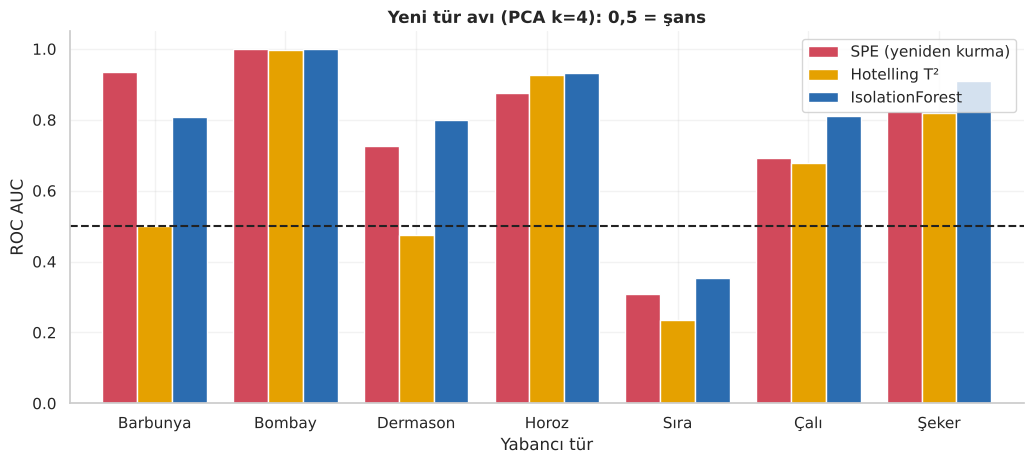

In [33]:
def anomali_skorlari(Xa, Xb_taniyik, Xb_yabanci, k):
    ol = StandardScaler().fit(Xa); Za = ol.transform(Xa); pc = PCA(k, random_state=RS).fit(Za)
    def spe_t2(Xn):
        Z = ol.transform(Xn); T = pc.transform(Z); geri = pc.inverse_transform(T)
        return ((Z - geri) ** 2).sum(1), (T ** 2 / pc.explained_variance_).sum(1)
    out = {}
    for ad, Xn in [("tan", Xb_taniyik), ("yab", Xb_yabanci)]: out[ad] = spe_t2(Xn)
    iso = IsolationForest(n_estimators=200, random_state=RS).fit(Za)
    out["iso"] = {"tan": -iso.score_samples(ol.transform(Xb_taniyik)), "yab": -iso.score_samples(ol.transform(Xb_yabanci))}
    return out

K_AN = K_95
satir = []
for j, t in enumerate(le.classes_):
    yab = Xtr[ytr == j]; tanik = Xtr[ytr != j]
    ta, tb = train_test_split(tanik, test_size=0.30, random_state=RS, stratify=ytr[ytr != j])
    o = anomali_skorlari(ta, tb, yab, K_AN); y_et = np.r_[np.zeros(len(tb)), np.ones(len(yab))]
    satir.append({"Yabancı tür": t, "n": len(yab), "SPE (yeniden kurma)": roc_auc_score(y_et, np.r_[o["tan"][0], o["yab"][0]]),
                  "Hotelling T²": roc_auc_score(y_et, np.r_[o["tan"][1], o["yab"][1]]),
                  "IsolationForest": roc_auc_score(y_et, np.r_[o["iso"]["tan"], o["iso"]["yab"]])})
an = pd.DataFrame(satir).set_index("Yabancı tür"); display(an.round(3)); rapor_kaydet(an, "26_yeni_tur_avi")

fig, ax = plt.subplots(figsize=(10.5, 4.8)); an.drop(columns="n").plot.bar(ax=ax, color=[RENK["pembe"], RENK["altin"], RENK["mavi"]], width=.8)
ax.axhline(0.5, color="#222", ls="--"); ax.set_ylabel("ROC AUC"); ax.set_ylim(0, 1.05); ax.set_title(f"Yeni tür avı (PCA k={K_AN}): 0,5 = şans"); ax.tick_params(axis="x", rotation=0)
fig.tight_layout(); kaydet(fig, "19_yeni_tur_avi"); plt.show()

In [34]:
iyi = an.drop(columns="n").max(axis=1).sort_values(ascending=False)
display(Markdown("**Okuma:** en kolay yakalanan yabancı türler: " + ", ".join(f"**{a}** (en iyi AUC {v:.2f})" for a, v in iyi.head(3).items()) +
                 "; en zor yakalananlar: " + ", ".join(f"**{a}** ({v:.2f})" for a, v in iyi.tail(3).items()) +
                 ". Bir tür diğerlerinin **ölçü aralığının içine** gömülüyse (örn. orta boy, orta şekil) hiçbir anomali yöntemi onu \"yabancı\" göremez."))

**Okuma:** en kolay yakalanan yabancı türler: **Bombay** (en iyi AUC 1.00), **Barbunya** (en iyi AUC 0.94), **Horoz** (en iyi AUC 0.93); en zor yakalananlar: **Çalı** (0.81), **Dermason** (0.80), **Sıra** (0.35). Bir tür diğerlerinin **ölçü aralığının içine** gömülüyse (örn. orta boy, orta şekil) hiçbir anomali yöntemi onu "yabancı" göremez.

<table><tr><td>

<img src="assets/etiket_dikkat.svg" height="34" alt="Dikkat">

Anomali tespiti, **gözetimsiz** olduğu için ucuzdur ama **kesin** değildir: yabancı tür bilinen türlerin tam arasındaysa kaçar. Gerçek bir hatta bu skor **"insana sor"** mekanizmasının ikinci bir sinyali olarak (güven eşiğiyle **birlikte**) düşünülmelidir. Burada her tür, **bilinmeyen sayıldığında** ölçüldüğü için sonuçlar bir **alt sınır tahminidir**.

</td></tr></table>

<a id="p15"></a>

<p align="center">
  <img src="assets/proje_15.svg" width="100%" alt="Bölüm 15">
</p>

### 💾 15.1 · Modeli Kaydet

Final boru hattı (ölçekleyici + PCA + model) **tek bir `joblib` dosyasına** kaydedilir: böylece hat işletmede aynı ölçekleme ve aynı PCA ile çalışır. Yanına **meta bilgi** (özellikler, sınıflar, sürümler, başarı) yazılır.

In [35]:
MODEL_DIR = Path("outputs/model"); MODEL_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(FINAL_TEST, MODEL_DIR / "fasulye_pca_model.joblib")
adim = FINAL_TEST.named_steps["pca"]
meta = {"proje": "Gün 54 — Kuru fasulye tasnifi (PCA)", "model": FINAL_AD, "ozellikler": OZELLIKLER, "siniflar_kodlu": {str(i): c for i, c in enumerate(le.classes_)},
        "pca_k": None if adim == "passthrough" else int(adim.n_components),
        "test": {k: round(float(v), 4) for k, v in tdict.items()}, "random_state": RANDOM_STATE,
        "surumler": {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "lightgbm": lightgbm.__version__, "numpy": np.__version__, "pandas": pd.__version__},
        "not": "Siniflar alfabetik (Turkce) sirada kodlanir; model sayisal etiket dondurur, fasulye_yardimci.tahmin_et Turkce ada cevirir."}
(MODEL_DIR / "meta.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8")
ornek = Xte.sample(5, random_state=RS).copy(); ornek["Gercek tur"] = le.classes_[yte[ornek.index]]
ornek.to_csv(MODEL_DIR / "ornek_fasulyeler.csv", index=False, encoding="utf-8-sig")
print("Kaydedilen:", sorted(p.name for p in MODEL_DIR.iterdir()), "| boyut:", round((MODEL_DIR / "fasulye_pca_model.joblib").stat().st_size / 1024), "KB")

Kaydedilen: ['fasulye_pca_model.joblib', 'meta.json', 'ornek_fasulyeler.csv'] | boyut: 446 KB


### 🧰 15.2 · Tahmin Fonksiyonu ve Ayrı Süreçte Yükleme Testi

In [36]:
# Not: model sayısal etiket (0..6) döndürür; tahmin_et() bunu Türkçe türe çevirir (fasulye_yardimci.py içinde)
def tahmin_tr(fasulye):
    """Tek fasulye (sözlük) veya tablo → Türkçe tür + güven."""
    X_ = pd.DataFrame([fasulye]) if isinstance(fasulye, dict) else pd.DataFrame(fasulye)
    p = FINAL_TEST.predict_proba(X_[OZELLIKLER]); return pd.DataFrame({"Tür": le.classes_[p.argmax(1)], "Güven": p.max(1).round(3)})

orn = pd.read_csv(MODEL_DIR / "ornek_fasulyeler.csv"); bu = tahmin_tr(orn[OZELLIKLER]); display(pd.concat([bu, orn["Gercek tur"]], axis=1))
# Depodaki yardımcı (fasulye_yardimci.tahmin_et) diskteki modeli kendisi yükler; aynı sonucu vermeli
yard = tahmin_et(orn[OZELLIKLER].iloc[0].to_dict()); print("tahmin_et (ilk örnek):", yard.iloc[0].to_dict(), "| bu süreç:", bu.iloc[0].to_dict())

# AYRI SÜREÇ: yeni bir Python süreci modeli diskten yükleyip aynı olasılıkları üretmeli
kod = ("import joblib, json, pandas as pd, numpy as np;"
       "m=joblib.load('outputs/model/fasulye_pca_model.joblib'); meta=json.load(open('outputs/model/meta.json',encoding='utf-8'));"
       "o=pd.read_csv('outputs/model/ornek_fasulyeler.csv'); p=m.predict_proba(o[meta['ozellikler']]);"
       "print(json.dumps(p.round(10).tolist()))")
cp = subprocess.run([sys.executable, "-W", "ignore", "-c", kod], capture_output=True, text=True, cwd=".")
p_ayri = np.array(json.loads(cp.stdout.strip().splitlines()[-1])); p_ici = FINAL_TEST.predict_proba(orn[OZELLIKLER])
print("Ayrı süreç ↔ bu süreç en büyük olasılık farkı:", float(np.abs(p_ayri - p_ici).max()))
assert np.allclose(p_ayri, p_ici, atol=1e-8), "Ayrı süreçte farklı sonuç!"
print("✅ Ayrı süreçte yükleme testi geçti.")

,Tür,Güven,Gercek tur
0,Şeker,0.990,Şeker
1,Horoz,0.999,Horoz
2,Sıra,0.879,Sıra
3,Sıra,0.553,Barbunya
4,Horoz,0.997,Horoz


tahmin_et (ilk örnek): {'Tür': 'Şeker', 'Güven': 0.99} | bu süreç: {'Tür': 'Şeker', 'Güven': 0.99}


Ayrı süreç ↔ bu süreç en büyük olasılık farkı: 4.8972684306251846e-11
✅ Ayrı süreçte yükleme testi geçti.


<table><tr><td>

<img src="assets/etiket_etik.svg" height="34" alt="Etik not">

Bu model **yalnızca bu 7 tür ve bu kamera düzeneğinin ölçüleri** için eğitildi. Başka bir kamera/ışık/ölçek, başka çeşitler ya da bozuk tanelerde başarısı **bilinmez**. Üretime çıkmadan önce yeni partilerde **izleme** (ölçü dağılımı kayması, güven dağılımı, anomali skoru) kurulmalıdır.

</td></tr></table>

<a id="p16"></a>

<p align="center">
  <img src="assets/proje_16.svg" width="100%" alt="Bölüm 16">
</p>

### 📋 16.1 · Proje Özeti (hücre çıktılarından üretilir)

In [37]:
lider_ad = yaris.index[0]
ozet = pd.DataFrame([
    ("Veri", f"{len(d)} fasulye (kopyasız), 16 ölçü, 7 tür; eğitim {len(Xtr)} / test {len(Xte)}"),
    ("Algoritma sayısı (taban hariç)", len(YARISCI) - 1),
    ("PCA k (önceden yazılmış %95 kuralı)", K_95),
    ("Ham dünyada lider (5 kat makro F1)", f"{lider_ad} · {yaris.loc[lider_ad, 'Ham F1']:.4f}"),
    ("PCA dünyasında lider", f"{yaris['PCA F1'].idxmax()} · {yaris['PCA F1'].max():.4f}"),
    ("Kural 2'yi geçen (ΔF1 ≥ −0,005 ve ≥ %30 hızlanma)", ", ".join(gecen) if gecen else "yok"),
    ("Final model (kural 3)", FINAL_AD),
    ("Final test: makro F1 / doğruluk / AUC", f"{tdict['Makro F1']:.4f} / {tdict['Doğruluk']:.4f} / {tdict['ROC AUC (OvR makro)']:.4f}"),
    ("Taban makro F1 (test)", f"{taban_f1:.3f}"),
    ("Güven eşiği ile otomatik kabul (test)", f"%{kabul.mean()*100:.1f} kabul, kabul edilenlerde doğruluk {(tah_te[kabul]==yte[kabul]).mean():.4f}"),
    ("Maliyete duyarlı karar (test)", f"toplam maliyet {mt.iloc[0,1]:.0f} → {mt.iloc[1,1]:.0f}"),
], columns=["Başlık", "Değer"])
display(ozet.style.hide(axis="index")); rapor_kaydet(ozet, "99_proje_ozeti", index=False)

Başlık,Değer
Veri,"13543 fasulye (kopyasız), 16 ölçü, 7 tür; eğitim 10834 / test 2709"
Algoritma sayısı (taban hariç),27
PCA k (önceden yazılmış %95 kuralı),4
Ham dünyada lider (5 kat makro F1),Oylama (yumuşak) · 0.9424
PCA dünyasında lider,SVM (RBF) · 0.8982
"Kural 2'yi geçen (ΔF1 ≥ −0,005 ve ≥ %30 hızlanma)",yok
Final model (kural 3),SVM (RBF) · PCA'sız
Final test: makro F1 / doğruluk / AUC,0.9389 / 0.9280 / 0.9940
Taban makro F1 (test),0.059
Güven eşiği ile otomatik kabul (test),"%88.3 kabul, kabul edilenlerde doğruluk 0.9674"


📄 Rapor → outputs/reports/99_proje_ozeti.csv


<table><tr><td>

<img src="assets/etiket_yonetici.svg" height="34" alt="Yönetici Özeti">

Bu bölümdeki tablo, **bu çalıştırmanın gerçek sayılarıdır**. Yönetici için üç cümle: (1) 16 şekil ölçüsü tür tahmini için güçlü bir temeldir; en iyi modeller çok yakın başarı verir ve **farkları şanstan ayırmak zordur**. (2) PCA ölçüleri birkaç bileşene sıkıştırır; **hız kazandırır** ama bileşen sayısı **ölçülerek** seçilmezse başarıyı düşürebilir. (3) Güven eşiği ile belirsiz fasulyeler **insana** yönlendirilirse otomatik kabul edilen kısımda hata oranı çok daha düşüktür.

</td></tr></table>

<p align="center">
  <img src="assets/kapanis_proje.svg" width="100%" alt="Kapanış">
</p>

### 🧠 Akılda Kalacaklar

<table>
<tr><td width="33%" valign="top" align="center"><h3>🧪</h3><b>Boru hattının içinde</b><br><sub><i>Scaler → PCA → Model</i></sub><br><br>PCA bir <b>öğrenmedir</b>; her katta yalnızca eğitim kısmında öğrenilir<br><br></td><td width="33%" valign="top" align="center"><h3>🎚️</h3><b>k bir düğmedir</b><br><sub><i>kural + doğrulama</i></sub><br><br>%95 kuralı bir <b>başlangıçtır</b>; model başarısıyla birlikte ayarla<br><br></td><td width="33%" valign="top" align="center"><h3>⚖️</h3><b>PCA bir takastır</b><br><sub><i>hız ↔ bilgi</i></sub><br><br>Etkisi <b>algoritmaya</b> ve veriye bağlı; her zaman ölç, genelleme<br><br></td></tr>
<tr><td width="33%" valign="top" align="center"><h3>🎲</h3><b>Fark gerçek mi?</b><br><sub><i>bootstrap</i></sub><br><br>Yakın skorlarda sıralama <b>şanstan</b> ayırt edilemeyebilir<br><br></td><td width="33%" valign="top" align="center"><h3>🙋</h3><b>Ne zaman susmalı?</b><br><sub><i>güven eşiği</i></sub><br><br>Belirsiz fasulyeyi <b>insana</b> sor; kabul edilen kısım daha güvenilir olur<br><br></td><td width="33%" valign="top" align="center"><h3>🚨</h3><b>PCA'nın ikinci işi</b><br><sub><i>yeniden kurma hatası</i></sub><br><br>Tanımadığı örnekleri <b>anomali</b> olarak işaretleyebilir (sınırlı)<br><br></td></tr>
</table>

### ❓ Quiz (cevaplar açılır kutularda)

<details><summary><b>1.</b> Neden ölçekleyici ve PCA boru hattının <i>içinde</i> olmalı?</summary>

Çünkü ikisi de **veriden öğrenir** (ortalama, standart sapma, eksenler). Çapraz doğrulamada her katın doğrulama kısmı, o katın öğrenmesinden **dışarıda** kalmalıdır; yoksa bilgi sızar ve skor iyimser olur.
</details>

<details><summary><b>2.</b> %95 varyans kuralı neden tek başına yeterli değildir?</summary>

Varyans **etiketten bağımsızdır**; sınıfları ayıran bilgi küçük varyanslı bir yönde olabilir. Bu yüzden `k`, **modelin başarısıyla** (k eğrisi, ayar) doğrulanır.
</details>

<details><summary><b>3.</b> PCA'dan sonra bazı modeller neden daha çok etkilenir?</summary>

Mesafeye dayalı ve doğrusal modeller tüm ölçüleri **birlikte** kullanır; bileşen sayısı azalınca bilgi azalır. Ağaç/boosting modelleri ise eksene paralel bölünmeler yaptığı için **döndürülmüş** bileşenlerde zorlanabilir. Etkiyi **ölçmeden** genellemeyin.
</details>

<details><summary><b>4.</b> Güven eşiği ve "insana sor" ne işe yarar?</summary>

Modelin **emin olmadığı** örnekleri insana yönlendirir; otomatik kabul edilen örneklerde doğruluk yükselir, bedeli **kabul oranının düşmesidir**. Eşik eğitim verisinin OOF tahminlerinden seçilir, testte yalnızca uygulanır.
</details>

<details><summary><b>5.</b> PCA ile anomali tespiti nasıl çalışır ve sınırı nedir?</summary>

Bilinen örneklerle PCA kurulur; yeni bir örnek bileşenlerle **iyi kurulamıyorsa** (yeniden kurma hatası büyük) şüphelidir. Yabancı tür bilinen türlerin **ölçü aralığının içindeyse** yakalanamaz.
</details>

### 🏠 Ödevler

1. Yarıştaki `k` değerini **%99 kuralına** (k = 6–7) çıkarıp 7.2–8.2 hücrelerini yeniden koşun: hangi algoritmalar kuralı geçiyor?
2. Ayar bölümüne **CatBoost**'u ekleyin (PCA'lı/PCA'sız) ve taze katlarda finalle kıyaslayın.
3. Maliyet matrisini **kendi senaryonuzla** değiştirin (örn. yalnızca Bombay hatası 10 birim); maliyet-duyarlı karar nasıl değişiyor?
4. Anomali bölümünde `k`'yı 2, 4, 8 yapıp **hangi türün yakalanabilirliği** değişiyor bakın.
5. *(Zor)* `PCA(whiten=True)` ve **Kernel PCA** (RBF) deneyin; kNN ve SVM başarısı değişiyor mu?

### 📚 KAYNAKÇA

Metin içi atıflar APA 7 biçimindedir. **Dolaylı atıf**, kaynağa ikinci elden ulaşıldığında "(B, A'dan aktarma)" kalıbıyla gösterilir; bu projedeki örnekler: *PCA'nın kökeni Pearson (1901) ve Hotelling (1933)'e dayanır (Pearson, 1901; Hotelling, 1933; Jolliffe ve Cadima, 2016'dan aktarma)*; *PCA'nın ön işleme adımı olarak çapraz doğrulama içinde yer alması gerektiği* Hastie ve ark. (2009) ile uyumludur. Bileşen sayısı kuralları için Cattell (1966), Kaiser (1960) ve Minka (2000) kullanılmıştır. *Not: Jolliffe ve Cadima (2016) ile Greenacre ve ark. (2022) makalelerinin tam metnine bu çalışma ortamından ulaşılamadı; künyeleri yayıncı/özet sayfalarından doğrulandı. Koklu ve Özkan (2020) için özet düzeyinde doğrulama yapıldı: dört model, 10 katlı çapraz doğrulama, SVM %93,13. Bu notebook'taki skorlar farklı bölme/kopya düzeni kullandığı için **doğrudan kıyaslanamaz**.*

- Bellman, R. (1961). *Adaptive control processes: A guided tour*. Princeton University Press.
- Cattell, R. B. (1966). The scree test for the number of factors. *Multivariate Behavioral Research, 1*(2), 245–276. https://doi.org/10.1207/s15327906mbr0102_10
- Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 785–794. https://doi.org/10.1145/2939672.2939785
- Greenacre, M., Groenen, P. J. F., Hastie, T., D'Enza, A. I., Markos, A., & Tuzhilina, E. (2022). Principal component analysis. *Nature Reviews Methods Primers, 2*, Article 100. https://doi.org/10.1038/s43586-022-00184-w
- Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The elements of statistical learning: Data mining, inference, and prediction* (2nd ed.). Springer.
- Hotelling, H. (1933). Analysis of a complex of statistical variables into principal components. *Journal of Educational Psychology, 24*(6), 417–441. https://doi.org/10.1037/h0071325
- Jolliffe, I. T., & Cadima, J. (2016). Principal component analysis: A review and recent developments. *Philosophical Transactions of the Royal Society A, 374*(2065), Article 20150202. https://doi.org/10.1098/rsta.2015.0202
- Kaiser, H. F. (1960). The application of electronic computers to factor analysis. *Educational and Psychological Measurement, 20*(1), 141–151. https://doi.org/10.1177/001316446002000116
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*, 3146–3154.
- Koklu, M., & Özkan, İ. A. (2020). Multiclass classification of dry beans using computer vision and machine learning techniques. *Computers and Electronics in Agriculture, 174*, Article 105507. https://doi.org/10.1016/j.compag.2020.105507
- Minka, T. P. (2000). Automatic choice of dimensionality for PCA. *Advances in Neural Information Processing Systems, 13*, 598–604.
- Pearson, K. (1901). On lines and planes of closest fit to systems of points in space. *The London, Edinburgh, and Dublin Philosophical Magazine and Journal of Science, 2*(11), 559–572. https://doi.org/10.1080/14786440109462720
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., … Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- Prokhorenkova, L., Gusev, G., Vorobev, A., Dorogush, A. V., & Gulin, A. (2018). CatBoost: Unbiased boosting with categorical features. *Advances in Neural Information Processing Systems, 31*, 6638–6648.
- Samancıoğlu, A. (t.y.). *Principal Component Analysis (PCA)* [Ders notu]. Yapay Zekâ ve Veri Bilimi Bootcamp.